# Margin-Template Rule Ensembles: Tabular Benchmark

Evaluates two compact differentiable rule-ensemble models against tabular baselines on 28 offline datasets.

## Proposed models
- **SMTE**: Student-t Margin Template Ensemble  
- **GMTE**: Gaussian Margin Template Ensemble  

## Baselines
- XGBoost
- CatBoost
- Explainable Boosting Machine, EBM
- RuleFit

## Datasets
- 13 regression datasets
- 15 classification datasets

In [1]:
!pip install -q interpret xgboost catboost imodels scikit-learn pandas numpy matplotlib seaborn torch scipy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 43.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.3/46.3 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 76.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.5/274.5 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 90.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 86.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 70.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.1/780.1 kB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 269.8/269.8 kB 20.5 MB/s eta 0:00:00


In [2]:
import os
import time
import math
import random
import warnings
from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, f1_score
from sklearn.multiclass import OneVsRestClassifier

from xgboost import XGBRegressor, XGBClassifier

from interpret.glassbox import (
    ExplainableBoostingRegressor,
    ExplainableBoostingClassifier,
)

try:
    from catboost import CatBoostRegressor, CatBoostClassifier
    HAS_CATBOOST = True
except Exception:
    HAS_CATBOOST = False

try:
    from imodels import RuleFitRegressor, RuleFitClassifier
    HAS_RULEFIT = True
except Exception:
    HAS_RULEFIT = False

warnings.filterwarnings("ignore")

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

OUTDIR = "outputs_extended"
os.makedirs(OUTDIR, exist_ok=True)

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:.4f}".format)

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def make_ohe():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

set_seed(SEED)

print(f"Device    : {DEVICE}")
print(f"CatBoost  : {HAS_CATBOOST}")
print(f"RuleFit   : {HAS_RULEFIT}")
print(f"Output dir: {OUTDIR}")

Device    : cuda
CatBoost  : True
RuleFit   : True
Output dir: outputs_extended


## 1. Dataset registry

In [3]:
LOCAL_DIR_REG = "/kaggle/input/datasets/crakly/ml-tabular-datasets/local_data/regression"
LOCAL_DIR_CLS = "/kaggle/input/datasets/crakly/ml-tabular-datasets/local_data/classification"

REGRESSION_DATASETS = [
    "California", "Diabetes", "Friedman1", "Friedman2", "Friedman3",
    "Abalone", "Concrete", "Energy", "Yacht", "Kin8nm", "Boston",
    "CPU_Act", "Auto_MPG",
]

CLASSIFICATION_DATASETS = [
    "Wine", "Iris", "Digits", "BreastCancer", "CovType",
    "Spambase", "Ionosphere", "Sonar", "Banknote", "Beans",
    "HeartStatlog", "Adult", "GermanCredit", "Vehicle", "Mushroom",
]

ALL_TASKS = (
    [("regression", ds) for ds in REGRESSION_DATASETS]
    + [("classification", ds) for ds in CLASSIFICATION_DATASETS]
)

print(f"Regression datasets    : {len(REGRESSION_DATASETS)}")
print(f"Classification datasets: {len(CLASSIFICATION_DATASETS)}")
print(f"Total datasets         : {len(ALL_TASKS)}")

def load_local_dataset(task: str, name: str):
    base_path = LOCAL_DIR_REG if task == "regression" else LOCAL_DIR_CLS
    x_path = os.path.join(base_path, f"{name}_X.csv")
    y_path = os.path.join(base_path, f"{name}_y.csv")

    if not os.path.exists(x_path) or not os.path.exists(y_path):
        raise FileNotFoundError(f"Missing files for {task}/{name}: {x_path}, {y_path}")

    X = pd.read_csv(x_path)
    y = pd.read_csv(y_path).squeeze()
    return X, y

Regression datasets    : 13
Classification datasets: 15
Total datasets         : 28


## 2. Preprocessing and split containers

In [4]:
@dataclass
class PreparedData:
    task: str
    feature_names: List[str]
    n_classes: int
    X_train: np.ndarray
    X_val: np.ndarray
    X_test: np.ndarray
    y_train_scaled: np.ndarray
    y_val_scaled: np.ndarray
    y_test_orig: np.ndarray
    y_scaler: Optional[StandardScaler]
    preprocessor: ColumnTransformer
    label_encoder: Optional[LabelEncoder]

def build_preprocessor(X: pd.DataFrame):
    numeric = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical = X.select_dtypes(exclude=[np.number]).columns.tolist()

    return ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                numeric,
            ),
            (
                "cat",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        ("onehot", make_ohe()),
                    ]
                ),
                categorical,
            ),
        ],
        remainder="drop",
    )

def transformed_feature_names(preprocessor: ColumnTransformer):
    try:
        return list(preprocessor.get_feature_names_out())
    except Exception:
        names = []
        for name, transformer, cols in preprocessor.transformers_:
            if name == "remainder":
                continue
            if name == "num":
                names.extend([f"num__{c}" for c in cols])
            elif name == "cat":
                try:
                    ohe = transformer.named_steps["onehot"]
                    names.extend(list(ohe.get_feature_names_out(cols)))
                except Exception:
                    names.extend([f"cat__{c}" for c in cols])
        return names

def prepare_dataset(task: str, ds_name: str, seed: int):
    X, y_raw = load_local_dataset(task, ds_name)

    label_encoder = None
    if task == "classification":
        label_encoder = LabelEncoder()
        y = pd.Series(label_encoder.fit_transform(y_raw))
        stratify = y
    else:
        y = pd.Series(pd.to_numeric(y_raw, errors="coerce"))
        stratify = None

    X_trainval, X_test, y_trainval, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=seed,
        stratify=stratify,
    )

    val_stratify = y_trainval if task == "classification" else None
    try:
        X_train, X_val, y_train, y_val = train_test_split(
            X_trainval,
            y_trainval,
            test_size=0.20,
            random_state=seed,
            stratify=val_stratify,
        )
    except ValueError:
        X_train, X_val, y_train, y_val = train_test_split(
            X_trainval,
            y_trainval,
            test_size=0.20,
            random_state=seed,
        )

    pre = build_preprocessor(X_train)
    X_train_t = pre.fit_transform(X_train).astype(np.float32)
    X_val_t = pre.transform(X_val).astype(np.float32)
    X_test_t = pre.transform(X_test).astype(np.float32)
    feature_names = transformed_feature_names(pre)

    if task == "regression":
        y_scaler = StandardScaler()
        y_train_scaled = y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel().astype(np.float32)
        y_val_scaled = y_scaler.transform(y_val.to_numpy().reshape(-1, 1)).ravel().astype(np.float32)
        y_test_orig = y_test.to_numpy().astype(np.float64)
        n_classes = 1
    else:
        y_scaler = None
        y_train_scaled = y_train.to_numpy().astype(np.int64)
        y_val_scaled = y_val.to_numpy().astype(np.int64)
        y_test_orig = y_test.to_numpy().astype(np.int64)
        n_classes = int(len(np.unique(y_train_scaled)))

    return PreparedData(
        task=task,
        feature_names=feature_names,
        n_classes=n_classes,
        X_train=X_train_t,
        X_val=X_val_t,
        X_test=X_test_t,
        y_train_scaled=y_train_scaled,
        y_val_scaled=y_val_scaled,
        y_test_orig=y_test_orig,
        y_scaler=y_scaler,
        preprocessor=pre,
        label_encoder=label_encoder,
    )

## 3. Margin-rule layer

In [5]:
@torch.no_grad()
def init_thresholds(th: torch.Tensor, X: np.ndarray, q_lo=0.10, q_hi=0.90, max_q=9):
    X = np.asarray(X, dtype=np.float32)
    R, D = th.shape

    for j in range(D):
        qn = min(R, max_q)
        qs = np.linspace(q_lo, q_hi, num=qn, dtype=np.float32)
        vals = np.quantile(X[:, j], qs).astype(np.float32)
        vals = np.resize(vals, R)
        th[:, j].copy_(torch.tensor(vals, dtype=torch.float32, device=th.device))

def log_margin(u: torch.Tensor, v: torch.Tensor, eps=1e-4):
    return torch.log(u + eps) - torch.log(v + eps)

class DualHeadMixin:
    def make_head(self, n_rules: int, n_classes: int):
        self.n_classes = n_classes
        return nn.Linear(n_rules, max(n_classes, 1))

    def supervised_loss(self, logits: torch.Tensor, y: torch.Tensor):
        if self.n_classes > 1:
            return F.cross_entropy(logits, y.long())
        return F.mse_loss(logits.view(-1), y.float())

class AxisAlignedMarginRuleLayer(nn.Module):
    def __init__(self, input_dim: int, n_rules: int = 64, beta: float = 6.0):
        super().__init__()
        self.input_dim = input_dim
        self.n_rules = n_rules
        self.beta = beta

        self.th = nn.Parameter(torch.zeros(n_rules, input_dim))
        self.ineq = nn.Parameter(torch.randn(n_rules, input_dim) * 0.1)
        self.esign = nn.Parameter(torch.randn(n_rules, input_dim) * 0.1)
        self.mask_logit = nn.Parameter(torch.full((n_rules, input_dim), -2.0))
        self.log_kappa = nn.Parameter(torch.tensor(math.log(6.0)))
        self.t = nn.Parameter(torch.zeros(n_rules))

    @torch.no_grad()
    def init_from_data(self, X: np.ndarray):
        init_thresholds(self.th, X)

    def literals(self, x: torch.Tensor):
        kappa = torch.exp(self.log_kappa).clamp(0.5, 50.0)
        direction = torch.tanh(self.ineq)[None, :, :]
        c = torch.sigmoid(kappa * direction * (x[:, None, :] - self.th[None, :, :]))

        mask = torch.sigmoid(self.mask_logit)[None, :, :]
        sign = torch.tanh(self.esign)[None, :, :]

        signed_literal = mask * sign * (2.0 * c - 1.0)
        positive = mask * (0.5 * (1.0 + sign) * c + 0.5 * (1.0 - sign) * (1.0 - c))
        negative = mask - positive

        return positive, negative, signed_literal, mask

    def forward(self, x: torch.Tensor):
        _, _, signed_literal, _ = self.literals(x)
        return torch.sigmoid(self.beta * (signed_literal.sum(dim=2) - self.t[None, :]))

## 4. Proposed models

In [6]:
class GaussianMarginTemplateEnsemble(DualHeadMixin, nn.Module):
    short_name = "GMTE"
    full_name = "Gaussian Margin Template Ensemble"

    def __init__(self, input_dim: int, n_rules: int = 64, n_classes: int = 1):
        super().__init__()
        self.rules = AxisAlignedMarginRuleLayer(input_dim=input_dim, n_rules=n_rules)
        self.loc = nn.Parameter(torch.zeros(n_rules, input_dim))
        self.scale = nn.Parameter(torch.ones(n_rules, input_dim))
        self.head = self.make_head(n_rules, n_classes)

    def init_from_data(self, X: np.ndarray):
        self.rules.init_from_data(X)

    def forward(self, x: torch.Tensor):
        u, v, _, _ = self.rules.literals(x)
        m = log_margin(u, v)
        s2 = F.softplus(self.scale)[None, :, :] ** 2 + 1e-6
        energy = -((m - self.loc[None, :, :]) ** 2 / (2.0 * s2)).sum(dim=2)
        z = torch.sigmoid(self.rules.beta * (energy - self.rules.t[None, :]))
        return self.head(z)

    def loss_batch(self, x: torch.Tensor, y: torch.Tensor):
        return self.supervised_loss(self.forward(x), y)

class StudentTMarginTemplateEnsemble(DualHeadMixin, nn.Module):
    short_name = "SMTE"
    full_name = "Student-t Margin Template Ensemble"

    def __init__(self, input_dim: int, n_rules: int = 64, n_classes: int = 1):
        super().__init__()
        self.rules = AxisAlignedMarginRuleLayer(input_dim=input_dim, n_rules=n_rules)
        self.mu = nn.Parameter(torch.zeros(n_rules, input_dim))
        self.log_s = nn.Parameter(torch.zeros(n_rules, input_dim))
        self.log_nu = nn.Parameter(torch.ones(n_rules) * math.log(5.0))
        self.head = self.make_head(n_rules, n_classes)

    def init_from_data(self, X: np.ndarray):
        self.rules.init_from_data(X)

    def forward(self, x: torch.Tensor):
        u, v, _, _ = self.rules.literals(x)
        m = log_margin(u, v)

        nu = F.softplus(self.log_nu).clamp(1.0, 50.0)
        s2 = F.softplus(self.log_s) ** 2 + 1e-6

        energy = -((nu[None, :, None] + 1.0) / 2.0) * torch.log1p(
            (m - self.mu[None, :, :]) ** 2 / (nu[None, :, None] * s2[None, :, :])
        )
        z = torch.sigmoid(self.rules.beta * (energy.sum(dim=2) - self.rules.t[None, :]))
        return self.head(z)

    def loss_batch(self, x: torch.Tensor, y: torch.Tensor):
        return self.supervised_loss(self.forward(x), y)

PROPOSED_MODELS = {
    "SMTE": StudentTMarginTemplateEnsemble,
    "GMTE": GaussianMarginTemplateEnsemble,
}

BASELINE_MODELS = ["EBM", "XGBoost", "CatBoost", "RuleFit"]
MODEL_ORDER = ["SMTE", "GMTE"] + BASELINE_MODELS

MODEL_COLORS = {
    "SMTE": "#2563EB",
    "GMTE": "#06B6D4",
    "EBM": "#8B5CF6",
    "XGBoost": "#4B5563",
    "CatBoost": "#F59E0B",
    "RuleFit": "#10B981",
}

## 5. Training, prediction, and baselines

In [7]:
N_RULES = 64
EPOCHS = 200
PATIENCE = 40
BATCH_SIZE = 512
LR = 3e-3
L1_MASK = 1e-4

SEEDS = [1, 12, 123, 1234, 12345]

STORE_EXAMPLE_DATASETS = ["California", "Friedman1", "Wine", "BreastCancer"]
example_models = {}
example_histories = {}
example_data = {}

def build_proposed_model(model_name: str, pp: PreparedData):
    model = PROPOSED_MODELS[model_name](
        input_dim=pp.X_train.shape[1],
        n_rules=N_RULES,
        n_classes=pp.n_classes,
    ).to(DEVICE)
    model.init_from_data(pp.X_train)
    return model

def train_proposed_model(model, pp: PreparedData):
    X_train = torch.tensor(pp.X_train, device=DEVICE)
    X_val = torch.tensor(pp.X_val, device=DEVICE)
    y_train = torch.tensor(pp.y_train_scaled, device=DEVICE)
    y_val = torch.tensor(pp.y_val_scaled, device=DEVICE)

    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-5)

    best_val = float("inf")
    best_state = None
    wait = 0

    history = {"train_loss": [], "val_loss": []}

    for epoch in range(EPOCHS):
        model.train()
        perm = torch.randperm(X_train.shape[0], device=DEVICE)
        batch_losses = []

        for i in range(0, X_train.shape[0], BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            xb, yb = X_train[idx], y_train[idx]

            opt.zero_grad()
            loss = model.loss_batch(xb, yb)
            loss = loss + L1_MASK * torch.sigmoid(model.rules.mask_logit).sum()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

            batch_losses.append(float(loss.detach().cpu()))

        sched.step()

        model.eval()
        with torch.no_grad():
            val_loss = float(model.loss_batch(X_val, y_val).detach().cpu())

        history["train_loss"].append(float(np.mean(batch_losses)))
        history["val_loss"].append(val_loss)

        if val_loss < best_val - 1e-5:
            best_val = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1

        if wait >= PATIENCE:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return history

@torch.no_grad()
def predict_proposed_model(model, pp: PreparedData):
    model.eval()
    out = model(torch.tensor(pp.X_test, device=DEVICE)).detach().cpu().numpy()

    if pp.task == "regression":
        return pp.y_scaler.inverse_transform(out.reshape(-1, 1)).ravel()

    return np.argmax(out, axis=1)

def evaluate_predictions(pp: PreparedData, pred: np.ndarray):
    if pp.task == "regression":
        return rmse(pp.y_test_orig, pred), "RMSE"

    return float(f1_score(pp.y_test_orig, pred, average="macro", zero_division=0)), "Macro-F1"

def proposed_complexity(model):
    with torch.no_grad():
        mask = torch.sigmoid(model.rules.mask_logit).detach().cpu().numpy()
        
        # Dynamic active literal cutoff based on rule's actual range
        active_counts = []
        for r in range(mask.shape[0]):
            cutoff = max(0.01, 0.25 * float(mask[r].max()))
            active_counts.append(np.sum(mask[r] > cutoff))
            
        entropy = -mask * np.log(mask + 1e-12) - (1.0 - mask) * np.log(1.0 - mask + 1e-12)

    return {
        "Params": int(sum(p.numel() for p in model.parameters())),
        "ActiveLiterals": float(np.mean(active_counts)),
        "MaskEntropy": float(np.mean(entropy)),
    }

def baseline_complexity(model_name: str, model):
    if model_name == "XGBoost":
        try:
            return {"Params": np.nan, "ActiveLiterals": np.nan, "MaskEntropy": np.nan, "Complexity": int(len(model.get_booster().get_dump()))}
        except Exception:
            return {"Params": np.nan, "ActiveLiterals": np.nan, "MaskEntropy": np.nan, "Complexity": np.nan}

    if model_name == "CatBoost":
        try:
            return {"Params": np.nan, "ActiveLiterals": np.nan, "MaskEntropy": np.nan, "Complexity": int(model.tree_count_)}
        except Exception:
            return {"Params": np.nan, "ActiveLiterals": np.nan, "MaskEntropy": np.nan, "Complexity": np.nan}

    if model_name == "EBM":
        try:
            return {"Params": np.nan, "ActiveLiterals": np.nan, "MaskEntropy": np.nan, "Complexity": int(len(model.term_names_))}
        except Exception:
            return {"Params": np.nan, "ActiveLiterals": np.nan, "MaskEntropy": np.nan, "Complexity": np.nan}

    if model_name == "RuleFit":
        try:
            rules = model.get_rules()
            return {"Params": np.nan, "ActiveLiterals": np.nan, "MaskEntropy": np.nan, "Complexity": int(len(rules))}
        except Exception:
            return {"Params": np.nan, "ActiveLiterals": np.nan, "MaskEntropy": np.nan, "Complexity": np.nan}

    return {"Params": np.nan, "ActiveLiterals": np.nan, "MaskEntropy": np.nan, "Complexity": np.nan}

def train_xgboost(pp: PreparedData, seed: int):
    if pp.task == "regression":
        model = XGBRegressor(
            n_estimators=400,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.85,
            colsample_bytree=0.85,
            objective="reg:squarederror",
            random_state=seed,
            n_jobs=-1,
            verbosity=0,
        )
        model.fit(pp.X_train, pp.y_train_scaled, eval_set=[(pp.X_val, pp.y_val_scaled)], verbose=False)
        pred = pp.y_scaler.inverse_transform(model.predict(pp.X_test).reshape(-1, 1)).ravel()
        return model, pred

    # classification
    kwargs = dict(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=seed,
        n_jobs=-1,
        verbosity=0,
    )

    if pp.n_classes > 2:
        kwargs["objective"] = "multi:softprob"
        kwargs["num_class"] = pp.n_classes
        kwargs["eval_metric"] = "mlogloss"
    else:
        kwargs["objective"] = "binary:logistic"
        kwargs["eval_metric"] = "logloss"

    model = XGBClassifier(**kwargs)
    model.fit(pp.X_train, pp.y_train_scaled, eval_set=[(pp.X_val, pp.y_val_scaled)], verbose=False)
    pred = model.predict(pp.X_test).astype(int)
    return model, pred

def train_catboost(pp: PreparedData, seed: int):
    if not HAS_CATBOOST:
        raise RuntimeError("CatBoost is unavailable.")

    if pp.task == "regression":
        model = CatBoostRegressor(
            iterations=500,
            depth=5,
            learning_rate=0.04,
            loss_function="RMSE",
            random_seed=seed,
            verbose=False,
        )
        model.fit(pp.X_train, pp.y_train_scaled, eval_set=(pp.X_val, pp.y_val_scaled), verbose=False)
        pred = pp.y_scaler.inverse_transform(model.predict(pp.X_test).reshape(-1, 1)).ravel()
    else:
        loss = "Logloss" if pp.n_classes == 2 else "MultiClass"
        model = CatBoostClassifier(
            iterations=500,
            depth=5,
            learning_rate=0.04,
            loss_function=loss,
            random_seed=seed,
            verbose=False,
        )
        model.fit(pp.X_train, pp.y_train_scaled, eval_set=(pp.X_val, pp.y_val_scaled), verbose=False)
        pred = model.predict(pp.X_test).astype(int).ravel()

    return model, pred

def train_ebm(pp: PreparedData, seed: int):
    if pp.task == "regression":
        model = ExplainableBoostingRegressor(
            interactions=10,
            random_state=seed,
            n_jobs=-1,
        )
        model.fit(pp.X_train, pp.y_train_scaled)
        pred = pp.y_scaler.inverse_transform(model.predict(pp.X_test).reshape(-1, 1)).ravel()
    else:
        model = ExplainableBoostingClassifier(
            interactions=10,
            random_state=seed,
            n_jobs=-1,
        )
        model.fit(pp.X_train, pp.y_train_scaled)
        pred = model.predict(pp.X_test).astype(int)

    return model, pred

def make_rulefit_regressor(seed: int):
    try:
        return RuleFitRegressor(
            n_estimators=200,
            tree_size=4,
            max_rules=300,
            random_state=seed,
        )
    except TypeError:
        return RuleFitRegressor(random_state=seed, max_rules=300)

def make_rulefit_classifier(seed: int):
    try:
        return RuleFitClassifier(
            n_estimators=200,
            tree_size=4,
            max_rules=300,
            random_state=seed,
        )
    except TypeError:
        return RuleFitClassifier(random_state=seed, max_rules=300)

def train_rulefit(pp: PreparedData, seed: int):
    if not HAS_RULEFIT:
        raise RuntimeError("RuleFit is unavailable.")

    if pp.task == "regression":
        model = make_rulefit_regressor(seed)
        try:
            model.fit(pp.X_train, pp.y_train_scaled, feature_names=pp.feature_names)
        except TypeError:
            model.fit(pp.X_train, pp.y_train_scaled)
        pred = pp.y_scaler.inverse_transform(model.predict(pp.X_test).reshape(-1, 1)).ravel()
    else:
        base = make_rulefit_classifier(seed)
        if pp.n_classes <= 2:
            model = base
            try:
                model.fit(pp.X_train, pp.y_train_scaled, feature_names=pp.feature_names)
            except TypeError:
                model.fit(pp.X_train, pp.y_train_scaled)
            pred = model.predict(pp.X_test).astype(int)
        else:
            model = OneVsRestClassifier(base)
            model.fit(pp.X_train, pp.y_train_scaled)
            pred = model.predict(pp.X_test).astype(int)

    return model, pred

BASELINE_TRAINERS = {
    "EBM": train_ebm,
    "XGBoost": train_xgboost,
    "CatBoost": train_catboost,
    "RuleFit": train_rulefit,
}

## 6. Benchmark execution

In [8]:
records = []
failed_runs = []

for task, ds_name in ALL_TASKS:
    print(f"\n{ds_name} | task={task}")

    for seed in SEEDS:
        set_seed(seed)

        try:
            pp = prepare_dataset(task, ds_name, seed)
        except Exception as e:
            failed_runs.append({"Task": task, "Dataset": ds_name, "Seed": seed, "Model": "DATA", "Error": str(e)})
            print(f"{ds_name:18s} | seed={seed:<6d} | DATA       | failed: {str(e)[:120]}")
            continue

        for model_name in MODEL_ORDER:
            set_seed(seed)
            t0 = time.time()

            try:
                if model_name in PROPOSED_MODELS:
                    model = build_proposed_model(model_name, pp)
                    history = train_proposed_model(model, pp)
                    pred = predict_proposed_model(model, pp)
                    metric, metric_label = evaluate_predictions(pp, pred)
                    complexity = proposed_complexity(model)
                    complexity["Complexity"] = complexity["Params"]
                    group = "Proposed"

                    if ds_name in STORE_EXAMPLE_DATASETS and seed == SEEDS[0]:
                        example_models[(ds_name, model_name)] = model.cpu()
                        example_histories[(ds_name, model_name)] = history
                        example_data[ds_name] = pp

                else:
                    trainer = BASELINE_TRAINERS[model_name]
                    model, pred = trainer(pp, seed)
                    metric, metric_label = evaluate_predictions(pp, pred)
                    complexity = baseline_complexity(model_name, model)
                    group = "Baseline"

                elapsed = time.time() - t0

                records.append({
                    "Task": task,
                    "Dataset": ds_name,
                    "Seed": seed,
                    "Model": model_name,
                    "Group": group,
                    "Metric": metric,
                    "MetricLabel": metric_label,
                    "Time": elapsed,
                    **complexity,
                    "NTrain": pp.X_train.shape[0],
                    "D": pp.X_train.shape[1],
                    "Classes": pp.n_classes,
                })

                print(
                    f"{ds_name:18s} | seed={seed:<6d} | {model_name:8s} | "
                    f"{metric_label:8s}={metric:10.4f} | time={elapsed:7.1f}s"
                )

            except Exception as e:
                failed_runs.append({
                    "Task": task,
                    "Dataset": ds_name,
                    "Seed": seed,
                    "Model": model_name,
                    "Error": str(e),
                })
                print(
                    f"{ds_name:18s} | seed={seed:<6d} | {model_name:8s} | "
                    f"failed: {str(e)[:120]}"
                )

df = pd.DataFrame(records)
df_fail = pd.DataFrame(failed_runs)

df.to_csv(f"{OUTDIR}/raw_benchmark_results.csv", index=False)
df_fail.to_csv(f"{OUTDIR}/failed_runs.csv", index=False)

display(df.head())


California | task=regression
California         | seed=1      | SMTE     | RMSE    =    0.4843 | time=   27.6s
California         | seed=1      | GMTE     | RMSE    =    0.4812 | time=   18.6s
California         | seed=1      | EBM      | RMSE    =    0.4703 | time=  195.3s
California         | seed=1      | XGBoost  | RMSE    =    0.4779 | time=    0.5s
California         | seed=1      | CatBoost | RMSE    =    0.4918 | time=    1.2s
California         | seed=1      | RuleFit  | RMSE    =    0.5586 | time= 1197.5s
California         | seed=12     | SMTE     | RMSE    =    0.4857 | time=   21.8s
California         | seed=12     | GMTE     | RMSE    =    0.4757 | time=   19.8s
California         | seed=12     | EBM      | RMSE    =    0.4665 | time=  180.9s
California         | seed=12     | XGBoost  | RMSE    =    0.4769 | time=    0.5s
California         | seed=12     | CatBoost | RMSE    =    0.4821 | time=    1.1s
California         | seed=12     | RuleFit  | RMSE    =    0.5435 | 

,Task,Dataset,Seed,Model,Group,Metric,MetricLabel,Time,Params,ActiveLiterals,MaskEntropy,Complexity,NTrain,D,Classes
0,regression,California,1,SMTE,Proposed,0.4843,RMSE,27.5631,3266.0000,2.6875,0.0492,3266.0000,13209,8,1
1,regression,California,1,GMTE,Proposed,0.4812,RMSE,18.5540,3202.0000,3.1562,0.0550,3202.0000,13209,8,1
2,regression,California,1,EBM,Baseline,0.4703,RMSE,195.3199,NaN,NaN,NaN,18.0000,13209,8,1
3,regression,California,1,XGBoost,Baseline,0.4779,RMSE,0.4734,NaN,NaN,NaN,400.0000,13209,8,1
4,regression,California,1,CatBoost,Baseline,0.4918,RMSE,1.1942,NaN,NaN,NaN,500.0000,13209,8,1


## 7. Ranking and paper tables

In [9]:
def add_ranks_and_scores(df: pd.DataFrame):
    out = []

    for _, g in df.groupby(["Task", "Dataset", "Seed"]):
        g = g.copy()
        task = g["Task"].iloc[0]
        lower_is_better = task == "regression"

        g["Rank"] = g["Metric"].rank(ascending=lower_is_better, method="average")

        x = g["Metric"].astype(float)
        if x.max() - x.min() < 1e-12:
            g["PerfScore"] = 0.5
        elif lower_is_better:
            g["PerfScore"] = 1.0 - (x - x.min()) / (x.max() - x.min())
        else:
            g["PerfScore"] = (x - x.min()) / (x.max() - x.min())

        out.append(g)

    return pd.concat(out, ignore_index=True)

if len(df) == 0:
    raise RuntimeError("No benchmark records were produced.")

df_ranked = add_ranks_and_scores(df)
df_ranked.to_csv(f"{OUTDIR}/ranked_benchmark_results.csv", index=False)

global_summary = (
    df_ranked
    .groupby(["Model", "Group"])
    .agg(
        AvgRank=("Rank", "mean"),
        MedianRank=("Rank", "median"),
        AvgPerfScore=("PerfScore", "mean"),
        MetricMean=("Metric", "mean"),
        MetricStd=("Metric", "std"),
        TimeMean=("Time", "mean"),
        TimeStd=("Time", "std"),
        Params=("Params", "mean"),
        Complexity=("Complexity", "mean"),
        ActiveLiterals=("ActiveLiterals", "mean"),
        MaskEntropy=("MaskEntropy", "mean"),
        Runs=("Metric", "size"),
    )
    .reset_index()
)

k_models = df_ranked["Model"].nunique()
global_summary["RankScore"] = 1.0 - (global_summary["AvgRank"] - 1.0) / max(k_models - 1.0, 1.0)
global_summary["PaperScore"] = 0.70 * global_summary["RankScore"] + 0.30 * global_summary["AvgPerfScore"]
global_summary = global_summary.sort_values("AvgRank").reset_index(drop=True)

task_summary = (
    df_ranked
    .groupby(["Task", "Model", "Group"])
    .agg(
        AvgRank=("Rank", "mean"),
        AvgPerfScore=("PerfScore", "mean"),
        MetricMean=("Metric", "mean"),
        MetricStd=("Metric", "std"),
        TimeMean=("Time", "mean"),
        Runs=("Metric", "size"),
    )
    .reset_index()
    .sort_values(["Task", "AvgRank"])
)

dataset_summary = (
    df_ranked
    .groupby(["Task", "Dataset", "Model"])
    .agg(
        AvgRank=("Rank", "mean"),
        AvgPerfScore=("PerfScore", "mean"),
        MetricMean=("Metric", "mean"),
        MetricStd=("Metric", "std"),
        TimeMean=("Time", "mean"),
    )
    .reset_index()
)

winner_rows = []
for (task, ds), g in dataset_summary.groupby(["Task", "Dataset"]):
    best = g.sort_values("AvgRank").iloc[0]
    winner_rows.append({
        "Task": task,
        "Dataset": ds,
        "Winner": best["Model"],
        "WinnerAvgRank": best["AvgRank"],
        "WinnerPerfScore": best["AvgPerfScore"],
        "MetricMean": best["MetricMean"],
    })

winner_table = pd.DataFrame(winner_rows).sort_values(["Task", "Dataset"])

global_summary.to_csv(f"{OUTDIR}/table_global_summary.csv", index=False)
task_summary.to_csv(f"{OUTDIR}/table_task_summary.csv", index=False)
dataset_summary.to_csv(f"{OUTDIR}/table_dataset_summary.csv", index=False)
winner_table.to_csv(f"{OUTDIR}/table_dataset_winners.csv", index=False)

display(global_summary)
display(task_summary)
display(winner_table.head(20))

,Model,Group,AvgRank,MedianRank,AvgPerfScore,MetricMean,MetricStd,TimeMean,TimeStd,Params,Complexity,ActiveLiterals,MaskEntropy,Runs,RankScore,PaperScore
0,EBM,Baseline,3.0214,3.0000,0.6699,5.3938,14.6189,45.6432,68.2691,NaN,36.7071,NaN,NaN,140,0.5957,0.6180
1,CatBoost,Baseline,3.0464,3.0000,0.7362,5.2290,14.0651,0.9628,0.8027,NaN,392.5643,NaN,NaN,140,0.5907,0.6344
2,SMTE,Proposed,3.1036,3.0000,0.6698,5.7980,16.7060,3.6749,4.5418,10754.8643,10754.8643,27.0939,0.2372,140,0.5793,0.6064
3,XGBoost,Baseline,3.4143,3.5000,0.6238,5.4334,13.9892,0.4120,0.4460,NaN,800.0000,NaN,NaN,140,0.5171,0.5492
4,GMTE,Proposed,3.5536,3.5000,0.5762,6.0551,16.7598,3.3795,3.8699,10690.8643,10690.8643,27.1113,0.2325,140,0.4893,0.5153
5,RuleFit,Baseline,4.8607,5.7500,0.2550,6.8863,18.5153,157.0186,244.6793,NaN,NaN,NaN,NaN,140,0.2279,0.2360


,Task,Model,Group,AvgRank,AvgPerfScore,MetricMean,MetricStd,TimeMean,Runs
0,classification,CatBoost,Baseline,3.0333,0.6844,0.8879,0.1054,1.3116,75
4,classification,SMTE,Proposed,3.2867,0.5975,0.8821,0.1102,2.9257,75
1,classification,EBM,Baseline,3.2933,0.6001,0.8888,0.1060,43.8424,75
5,classification,XGBoost,Baseline,3.3600,0.5875,0.8868,0.1017,0.5476,75
2,classification,GMTE,Proposed,3.5267,0.5325,0.8796,0.1139,2.7271,75
3,classification,RuleFit,Baseline,4.5000,0.3171,0.8731,0.1148,79.8336,75
7,regression,EBM,Baseline,2.7077,0.7505,10.5918,20.3205,47.7212,65
10,regression,SMTE,Proposed,2.8923,0.7531,11.4702,23.3483,4.5395,65
6,regression,CatBoost,Baseline,3.0615,0.7960,10.2380,19.5467,0.5602,65
11,regression,XGBoost,Baseline,3.4769,0.6658,10.6794,19.3092,0.2554,65


,Task,Dataset,Winner,WinnerAvgRank,WinnerPerfScore,MetricMean
0,classification,Adult,EBM,2.6000,0.7821,0.7894
1,classification,Banknote,CatBoost,2.2000,0.8999,0.9993
2,classification,Beans,XGBoost,1.8000,0.9284,0.8897
3,classification,BreastCancer,GMTE,2.5000,0.7637,0.9715
4,classification,CovType,XGBoost,1.0000,1.0000,0.8420
5,classification,Digits,CatBoost,1.6000,0.9012,0.9788
6,classification,GermanCredit,SMTE,2.6000,0.7387,0.6702
7,classification,HeartStatlog,EBM,1.8000,0.8922,0.8596
8,classification,Ionosphere,EBM,2.1000,0.8000,0.9343
9,classification,Iris,GMTE,3.0000,0.7000,0.9666


## 8. Paper plotting style

In [10]:
def set_paper_style():
    sns.set_theme(style="whitegrid", context="paper")
    plt.rcParams.update({
        "figure.dpi": 300,
        "savefig.dpi": 600,
        "font.family": "serif",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "legend.fontsize": 9,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
    })

def savefig(name: str):
    plt.savefig(f"{OUTDIR}/{name}.png", bbox_inches="tight")

set_paper_style()

## 9. Figure 1 — Critical-difference style average-rank diagram

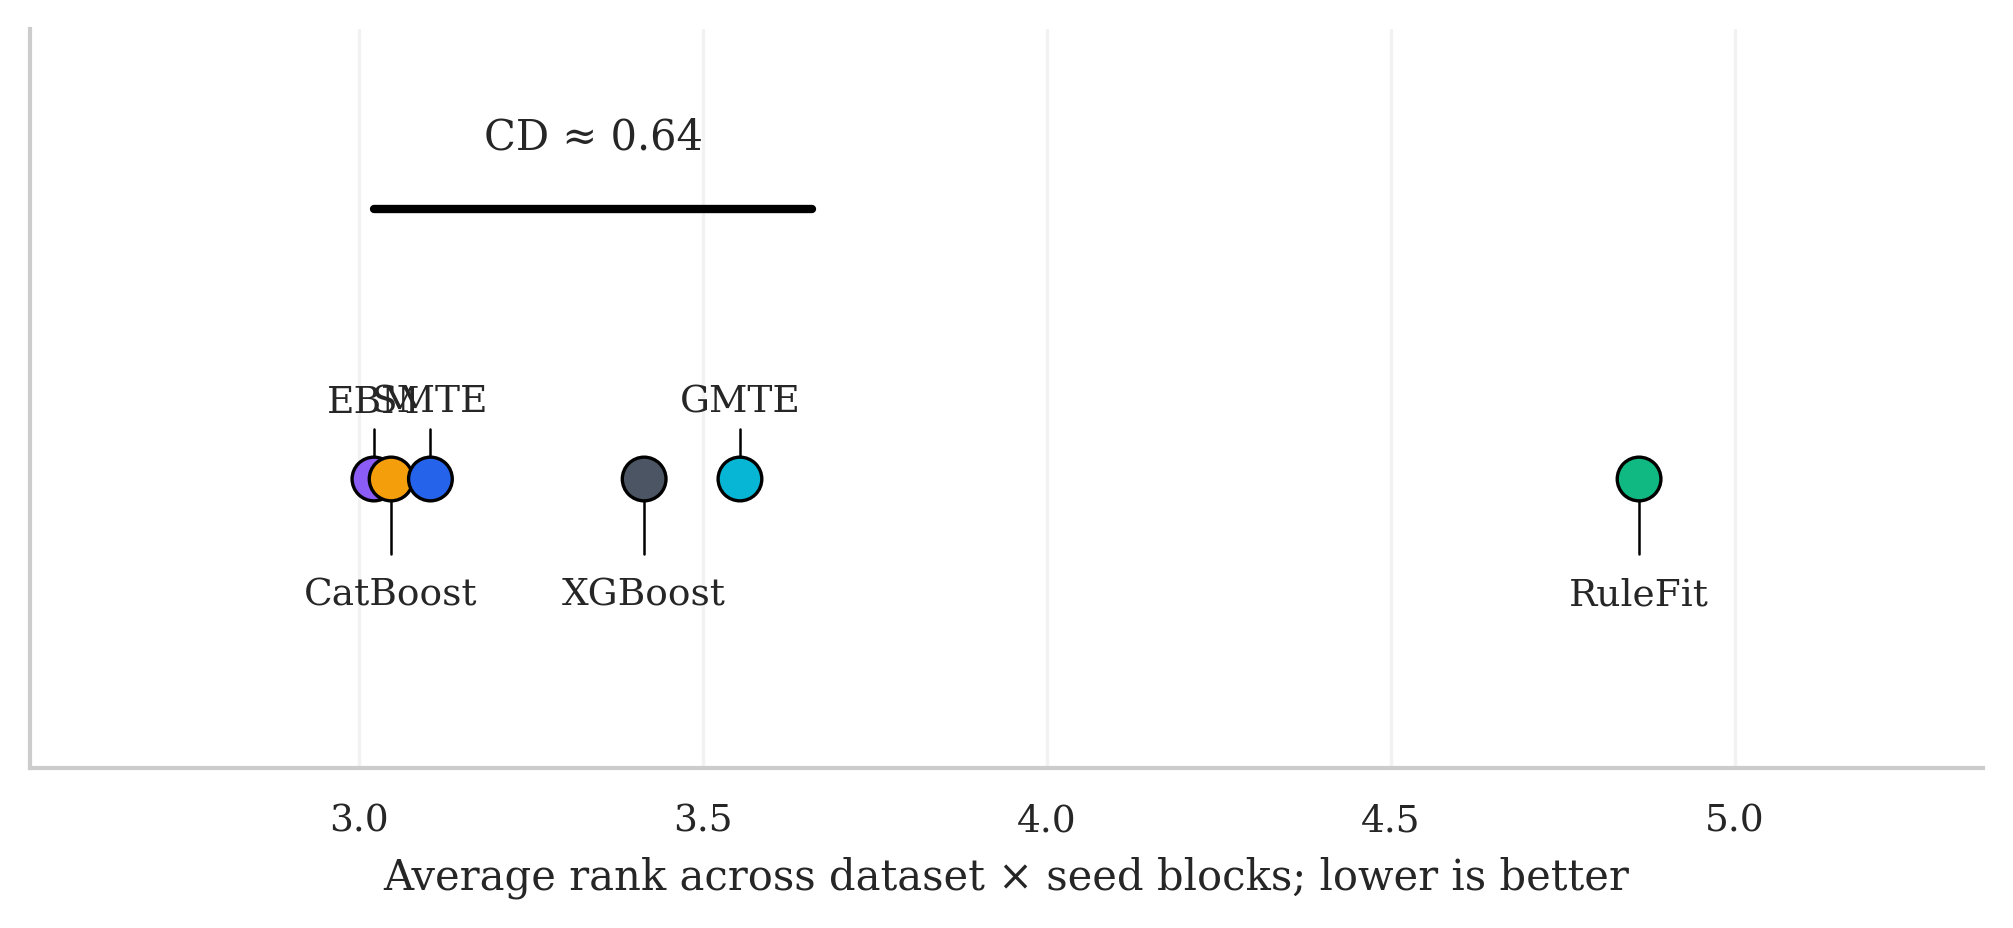

In [11]:
avg_rank = global_summary.set_index("Model")["AvgRank"].sort_values()
models = avg_rank.index.tolist()
ranks = avg_rank.values

N_blocks = df_ranked.groupby(["Dataset", "Seed"]).ngroups
k = len(models)
q_alpha = 2.85
cd = q_alpha * math.sqrt(k * (k + 1) / (6.0 * max(N_blocks, 1)))

fig, ax = plt.subplots(figsize=(8.4, 3.2))

y = np.zeros(len(models))
ax.scatter(ranks, y, s=110, color=[MODEL_COLORS.get(m, "#777777") for m in models], edgecolor="black", zorder=3)

for i, m in enumerate(models):
    dy = 0.12 if i % 2 == 0 else -0.18
    ax.plot([ranks[i], ranks[i]], [0, dy * 0.65], color="black", linewidth=0.6)
    ax.text(ranks[i], dy, m, ha="center", va="center", fontsize=9)

x0 = ranks.min()
ax.plot([x0, x0 + cd], [0.42, 0.42], color="black", linewidth=2)
ax.text(x0 + cd / 2, 0.50, f"CD ≈ {cd:.2f}", ha="center", va="bottom")

ax.set_ylim(-0.45, 0.70)
ax.set_xlim(max(0.8, ranks.min() - 0.5), ranks.max() + 0.5)
ax.set_yticks([])
ax.set_xlabel("Average rank across dataset × seed blocks; lower is better")
ax.grid(axis="x", alpha=0.25)

savefig("figure_1_average_rank_cd")
plt.show()

## 10. Figure 2 — Dataset performance heatmap

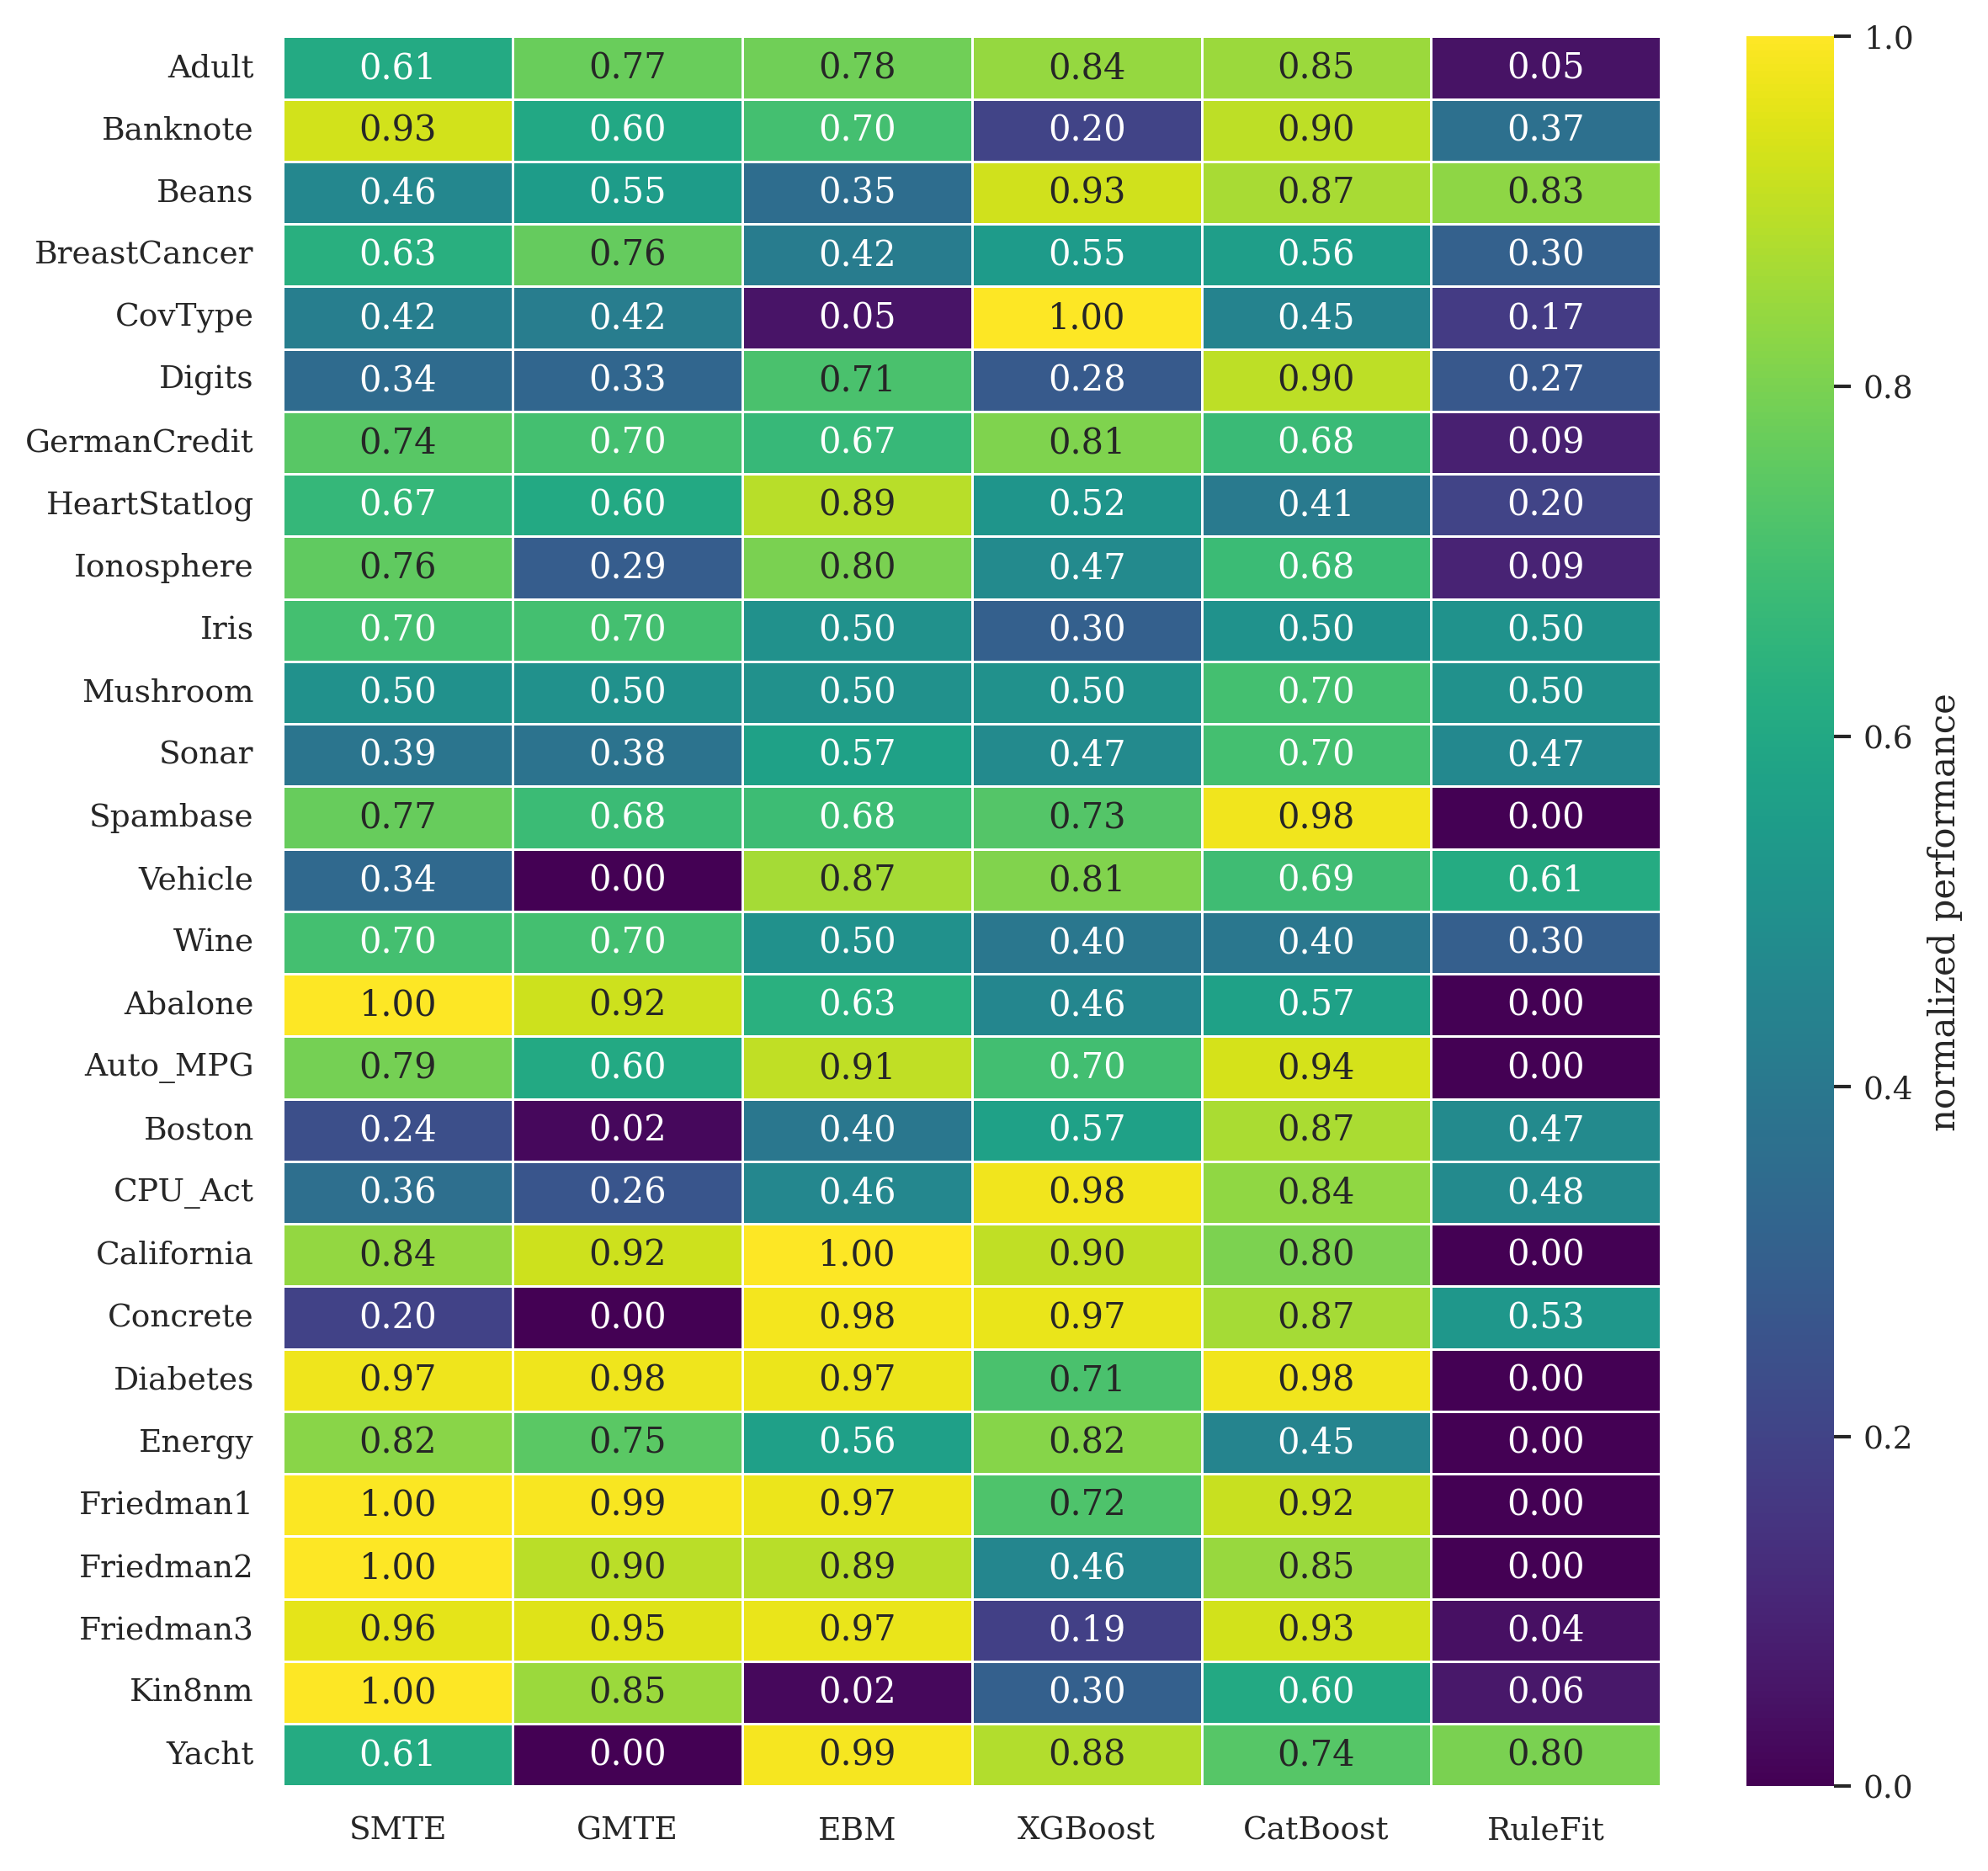

In [12]:
heat = (
    df_ranked
    .groupby(["Dataset", "Model"])["PerfScore"]
    .mean()
    .reset_index()
    .pivot(index="Dataset", columns="Model", values="PerfScore")
)

ordered_datasets = (
    df_ranked[["Task", "Dataset"]]
    .drop_duplicates()
    .sort_values(["Task", "Dataset"])
    ["Dataset"]
    .tolist()
)

heat = heat.loc[[d for d in ordered_datasets if d in heat.index], [m for m in MODEL_ORDER if m in heat.columns]]

fig, ax = plt.subplots(figsize=(8.8, 9.0))
sns.heatmap(
    heat,
    cmap="viridis",
    vmin=0,
    vmax=1,
    linewidths=0.35,
    linecolor="white",
    annot=True,
    fmt=".2f",
    cbar_kws={"label": "normalized performance"},
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("")
savefig("figure_2_dataset_performance_heatmap")
plt.show()

## 11. Figure 3 — Efficiency frontier

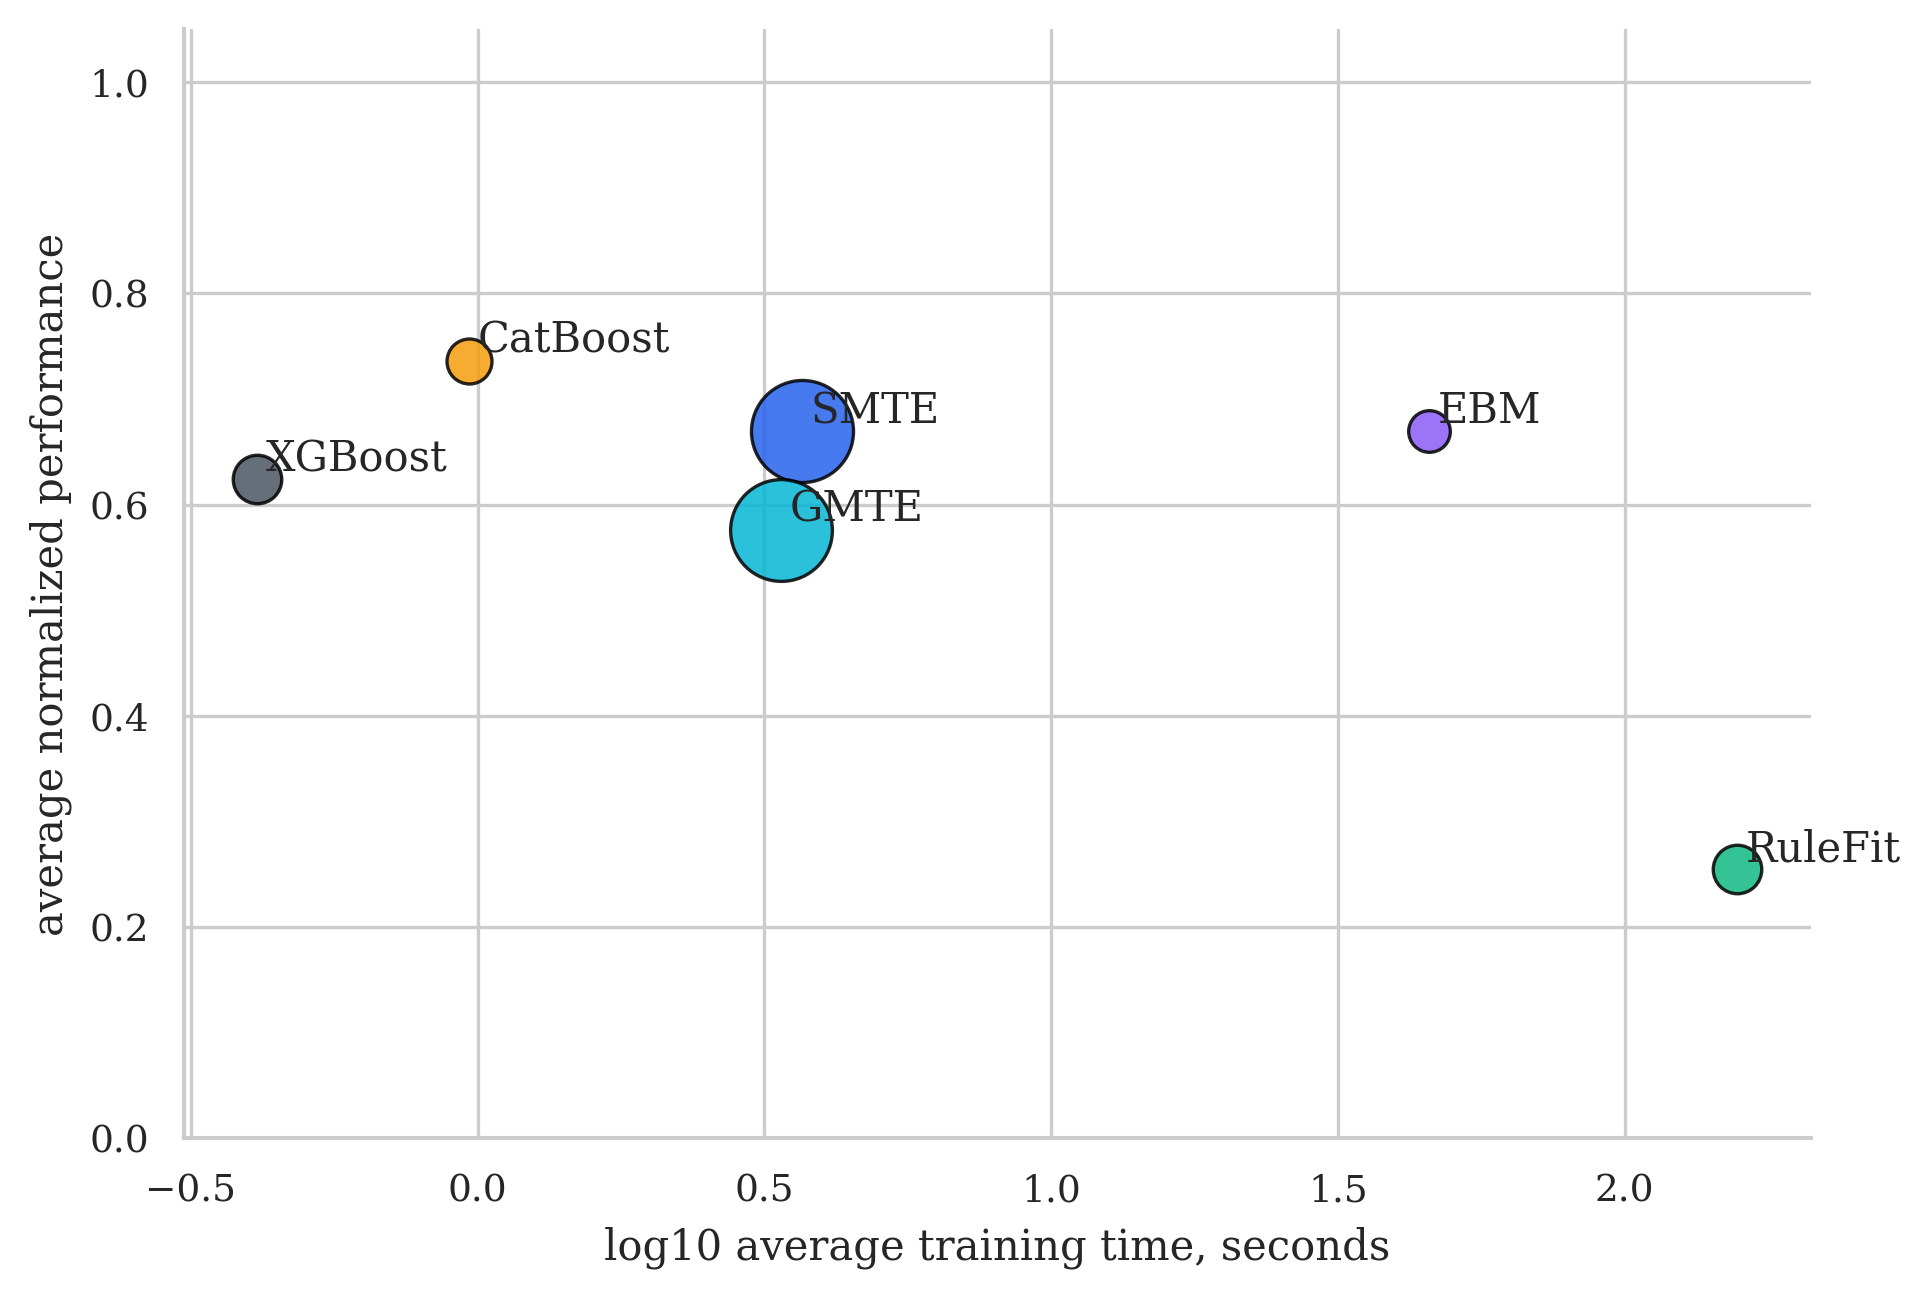

In [13]:
frontier = global_summary.copy()
frontier["LogTime"] = np.log10(frontier["TimeMean"] + 1e-3)

size_base = frontier["Complexity"].replace([np.inf, -np.inf], np.nan)
if size_base.notna().sum() > 0:
    sizes = 100 + 500 * (size_base.fillna(size_base.median()) - size_base.min()) / (size_base.max() - size_base.min() + 1e-12)
else:
    sizes = pd.Series(np.full(len(frontier), 250.0), index=frontier.index)

fig, ax = plt.subplots(figsize=(7.0, 4.8))

for i, row in frontier.iterrows():
    m = row["Model"]
    ax.scatter(
        row["LogTime"],
        row["AvgPerfScore"],
        s=float(sizes.loc[i]),
        color=MODEL_COLORS.get(m, "#777777"),
        edgecolor="black",
        alpha=0.85,
    )
    ax.text(row["LogTime"] + 0.015, row["AvgPerfScore"] + 0.008, m)

ax.set_xlabel("log10 average training time, seconds")
ax.set_ylabel("average normalized performance")
ax.set_ylim(0, 1.05)
savefig("figure_3_efficiency_frontier")
plt.show()

## 12. Figure 4 — Pairwise win matrix

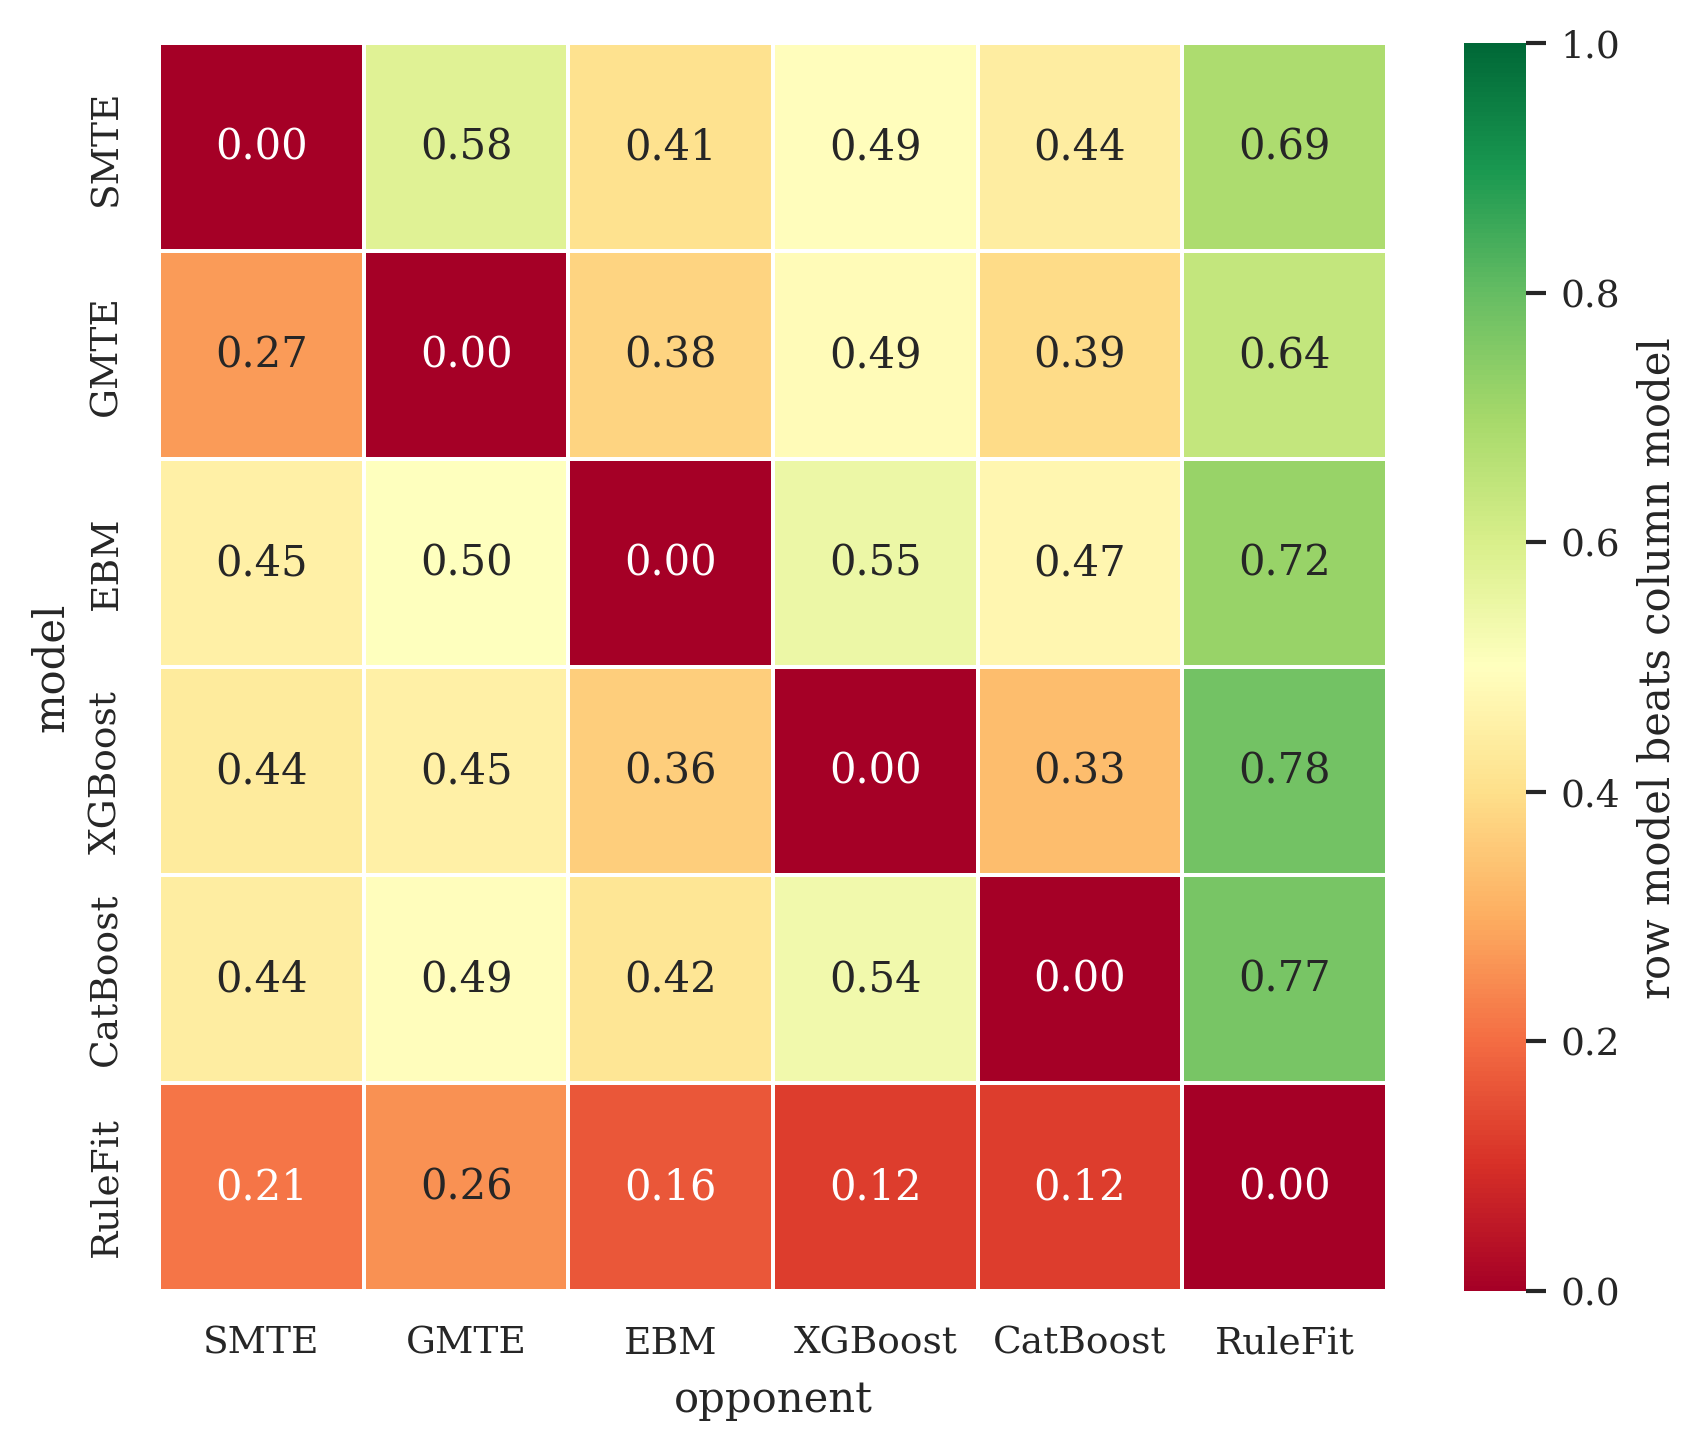

In [14]:
rank_pivot = df_ranked.pivot_table(
    index=["Task", "Dataset", "Seed"],
    columns="Model",
    values="Rank",
    aggfunc="mean",
)

present_models = [m for m in MODEL_ORDER if m in rank_pivot.columns]
win = pd.DataFrame(np.nan, index=present_models, columns=present_models)

for a in present_models:
    for b in present_models:
        valid = rank_pivot[[a, b]].dropna()
        if len(valid) == 0:
            continue

        a_vals = valid[[a]].to_numpy()
        b_vals = valid[[b]].to_numpy()
        win.loc[a, b] = float((a_vals < b_vals).mean())

fig, ax = plt.subplots(figsize=(6.6, 5.4))
sns.heatmap(
    win,
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "row model beats column model"},
    ax=ax,
)
ax.set_xlabel("opponent")
ax.set_ylabel("model")
savefig("figure_4_pairwise_win_matrix")
plt.show()

win.to_csv(f"{OUTDIR}/table_pairwise_win_matrix.csv")

## 13. Figure 5 — Task-wise rank profile

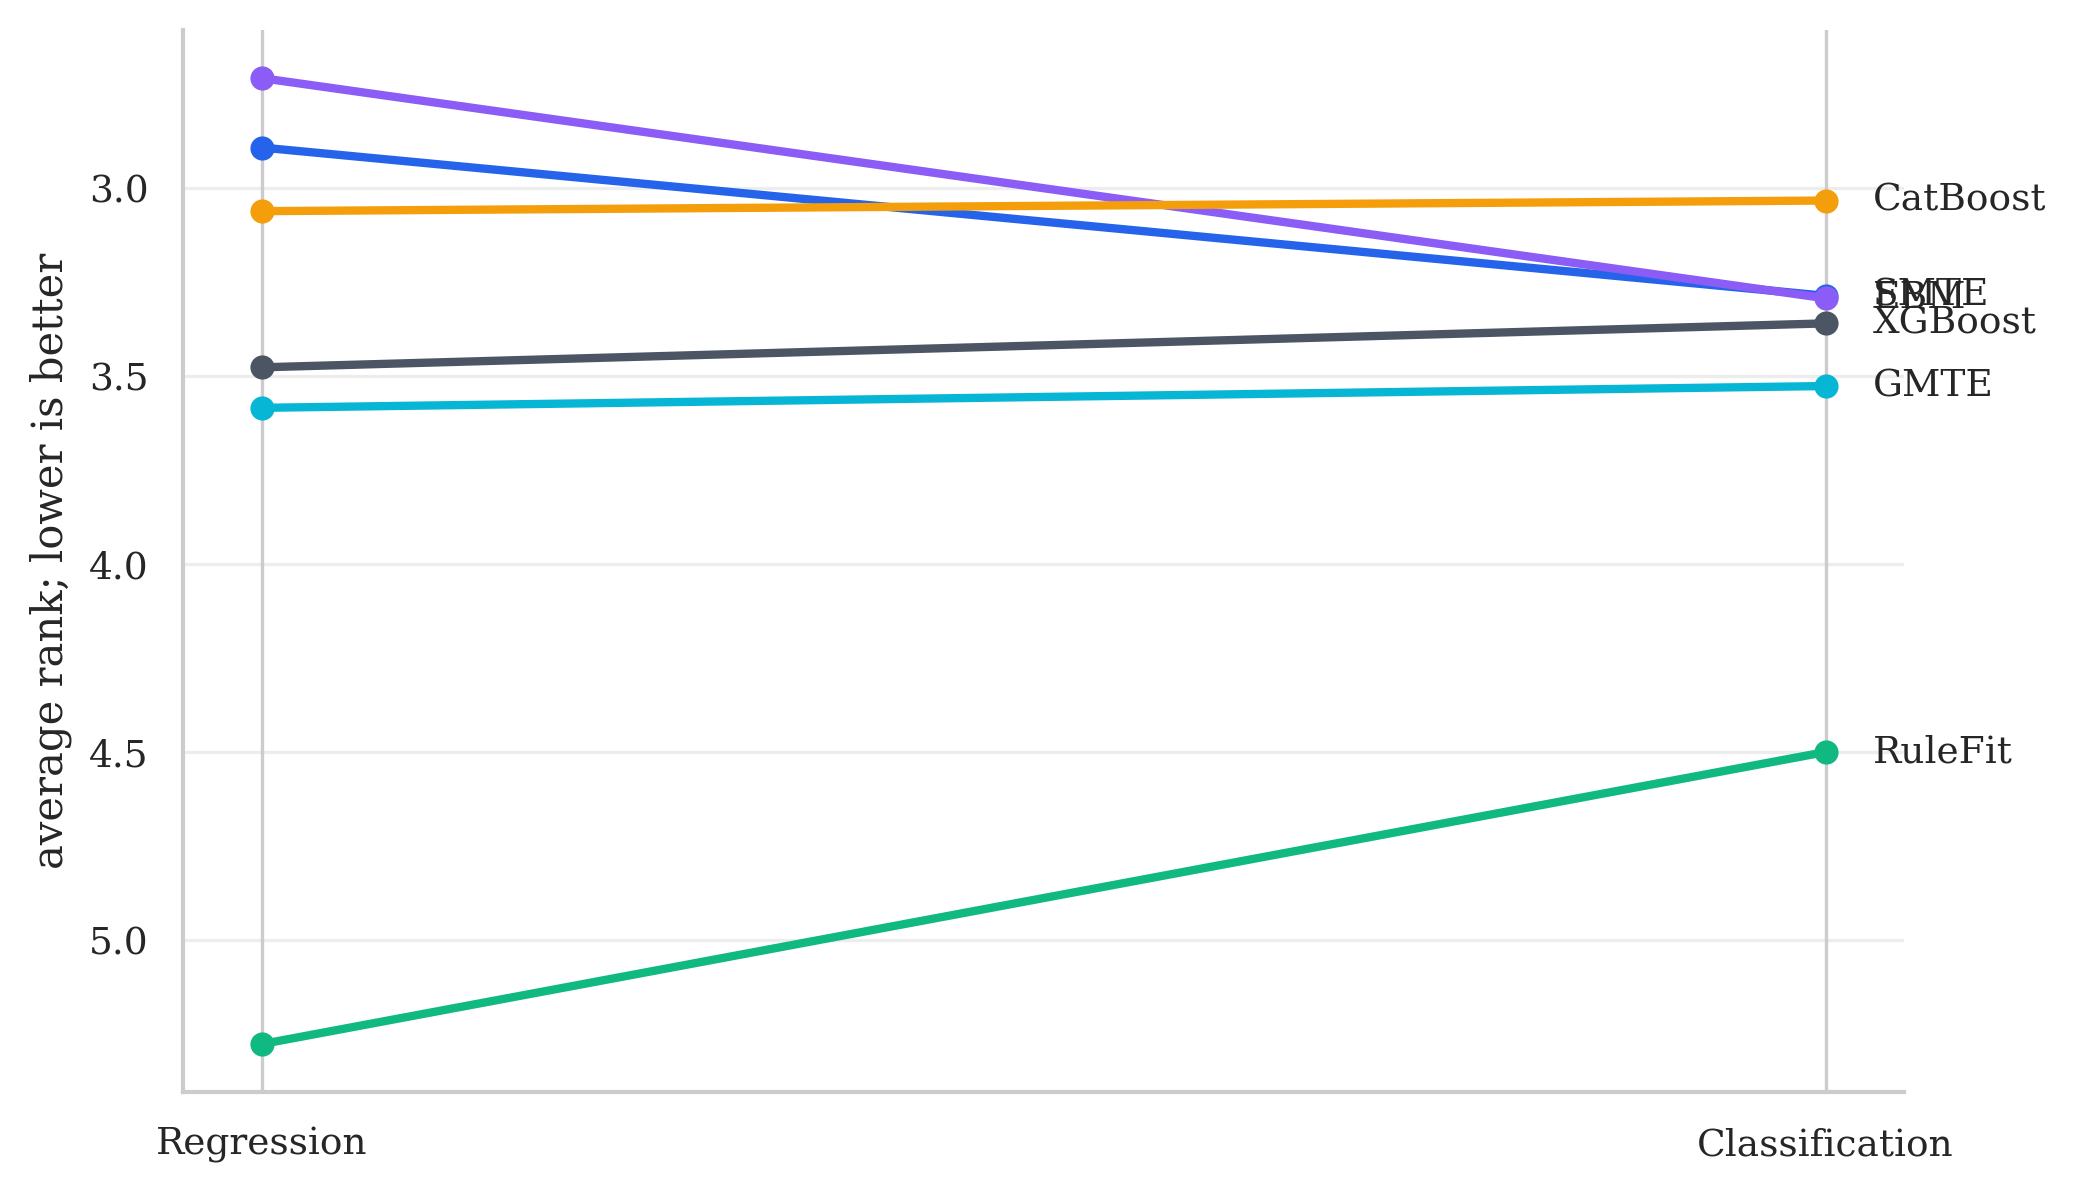

In [15]:
task_rank = (
    task_summary
    .pivot(index="Model", columns="Task", values="AvgRank")
    .reindex([m for m in MODEL_ORDER if m in task_summary["Model"].unique()])
)

fig, ax = plt.subplots(figsize=(7.4, 4.6))

for m in task_rank.index:
    if "regression" not in task_rank.columns or "classification" not in task_rank.columns:
        continue

    x = [0, 1]
    y = [task_rank.loc[m, "regression"], task_rank.loc[m, "classification"]]
    ax.plot(x, y, marker="o", linewidth=2, color=MODEL_COLORS.get(m, "#777777"), label=m)
    ax.text(1.03, y[1], m, va="center", fontsize=9)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Regression", "Classification"])
ax.set_ylabel("average rank; lower is better")
ax.invert_yaxis()
ax.grid(axis="y", alpha=0.35)
savefig("figure_5_task_rank_profile")
plt.show()

## 14. Figure 6 — Rank distribution

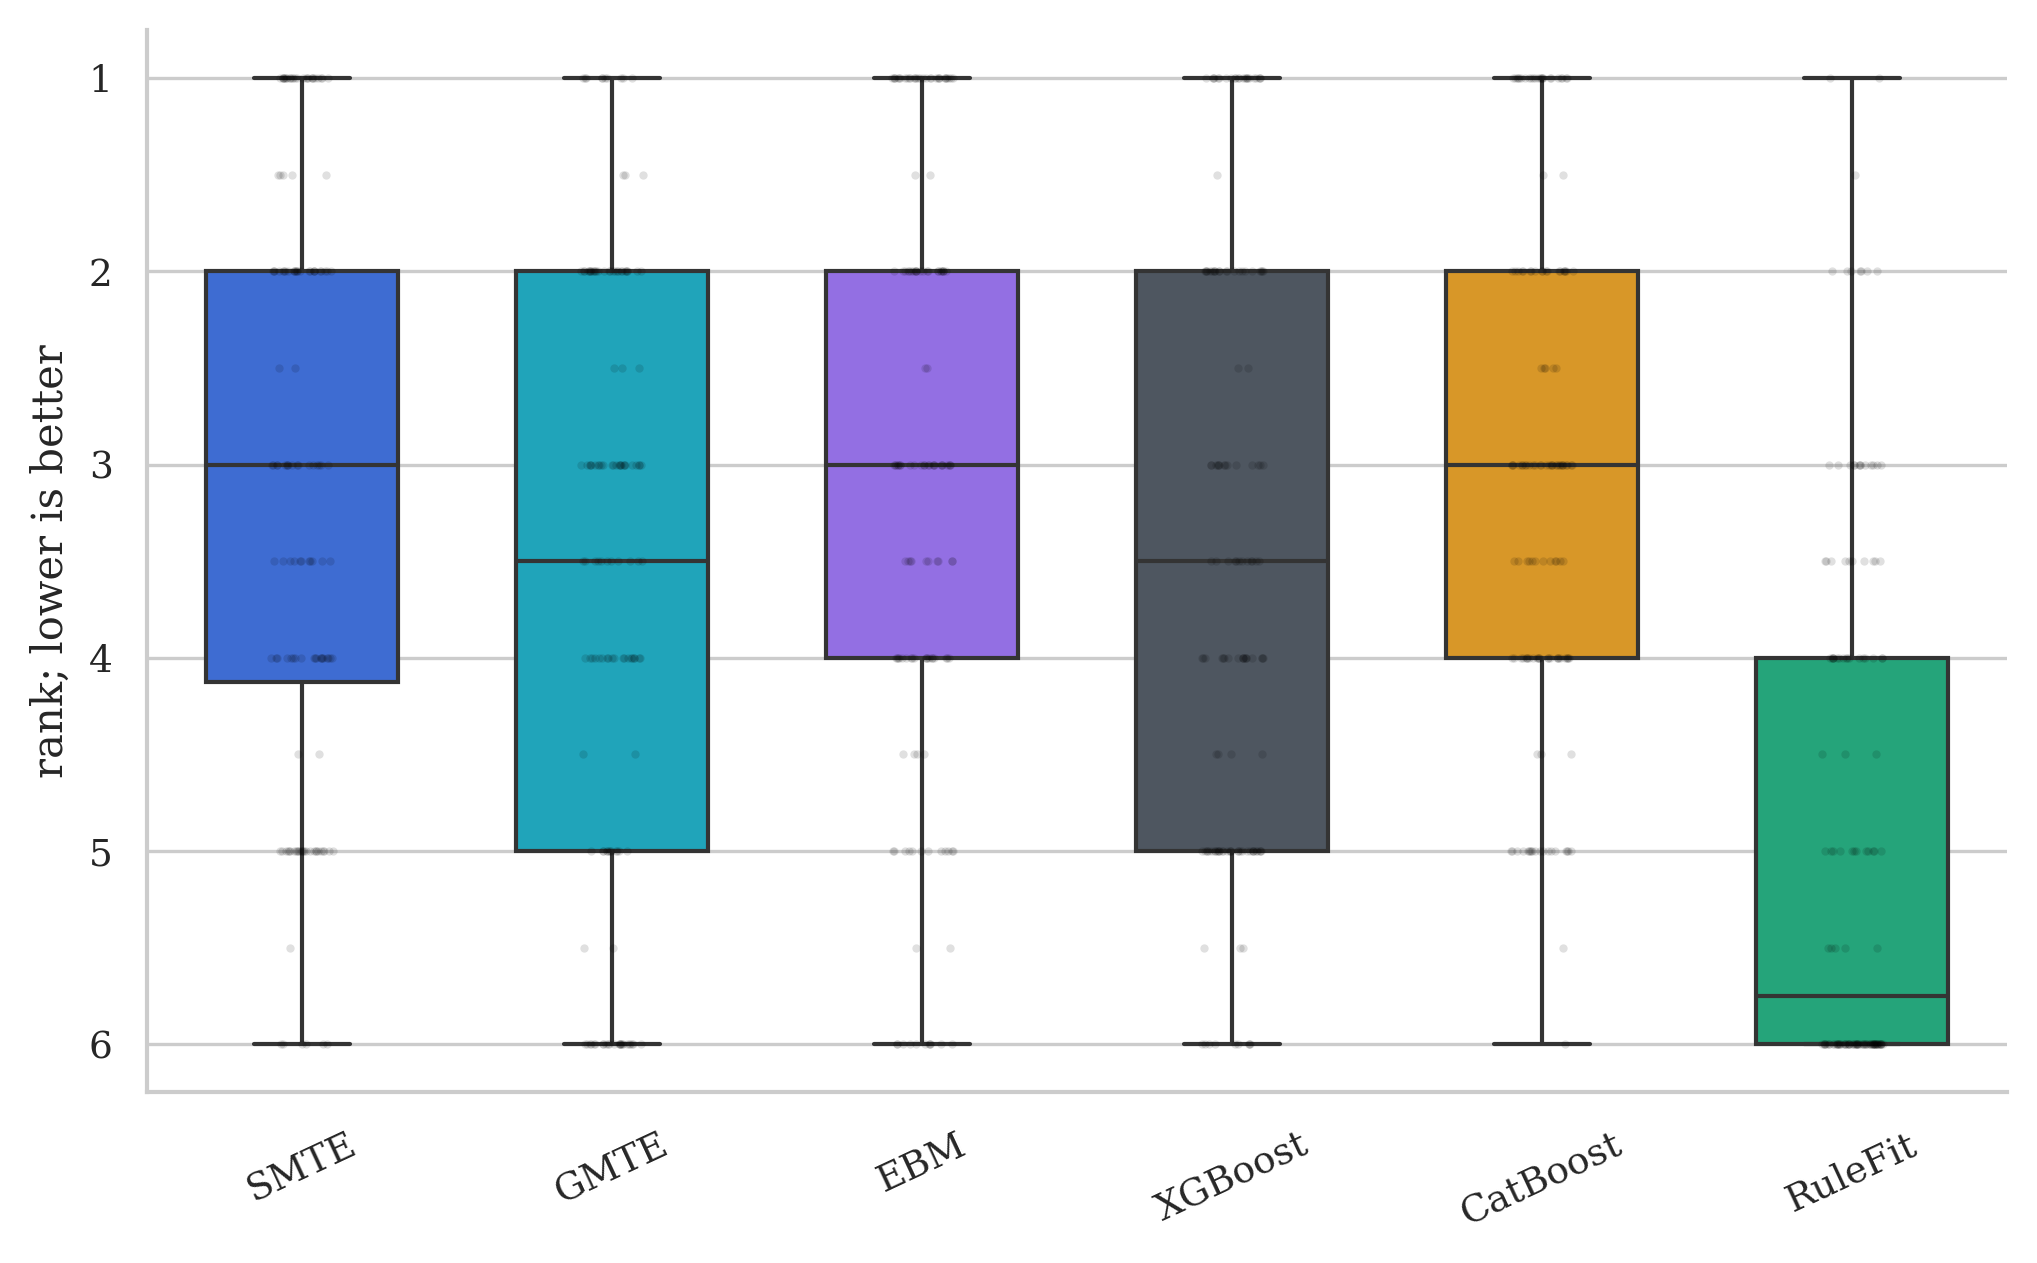

In [16]:
fig, ax = plt.subplots(figsize=(8.0, 4.6))

plot_df = df_ranked[df_ranked["Model"].isin(MODEL_ORDER)].copy()
sns.boxplot(
    data=plot_df,
    x="Model",
    y="Rank",
    order=[m for m in MODEL_ORDER if m in plot_df["Model"].unique()],
    palette=MODEL_COLORS,
    width=0.62,
    fliersize=2,
    ax=ax,
)

sns.stripplot(
    data=plot_df.sample(min(len(plot_df), 1200), random_state=SEED),
    x="Model",
    y="Rank",
    order=[m for m in MODEL_ORDER if m in plot_df["Model"].unique()],
    color="black",
    alpha=0.12,
    size=2,
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("rank; lower is better")
ax.invert_yaxis()
ax.tick_params(axis="x", rotation=25)
savefig("figure_6_rank_distribution")
plt.show()

## 15. Figure 7 — Learned margin-rule structure

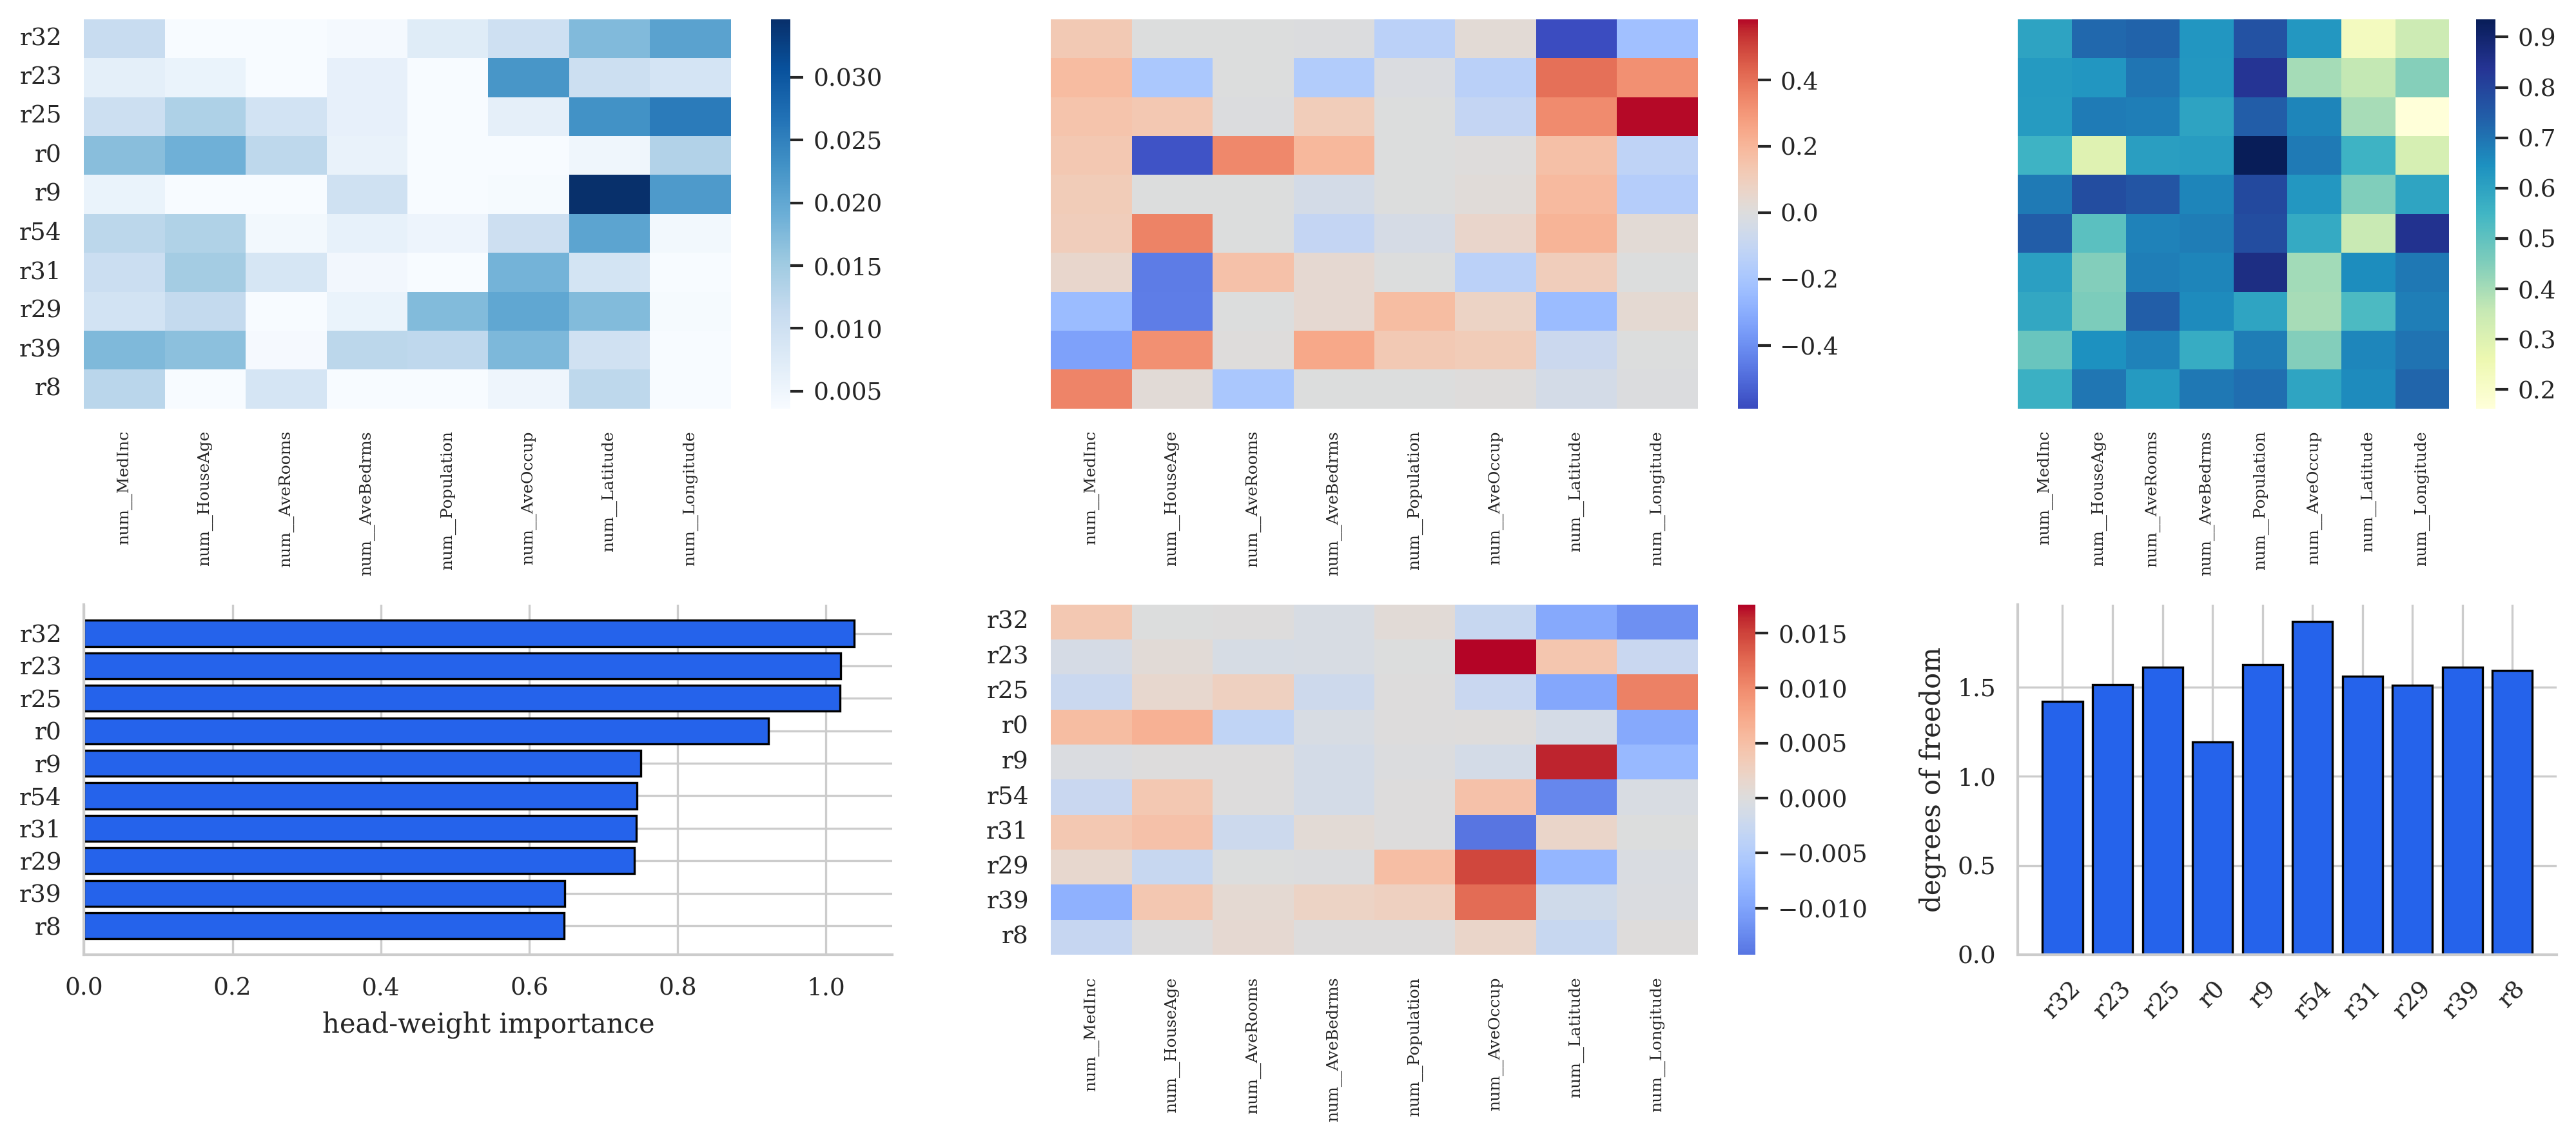

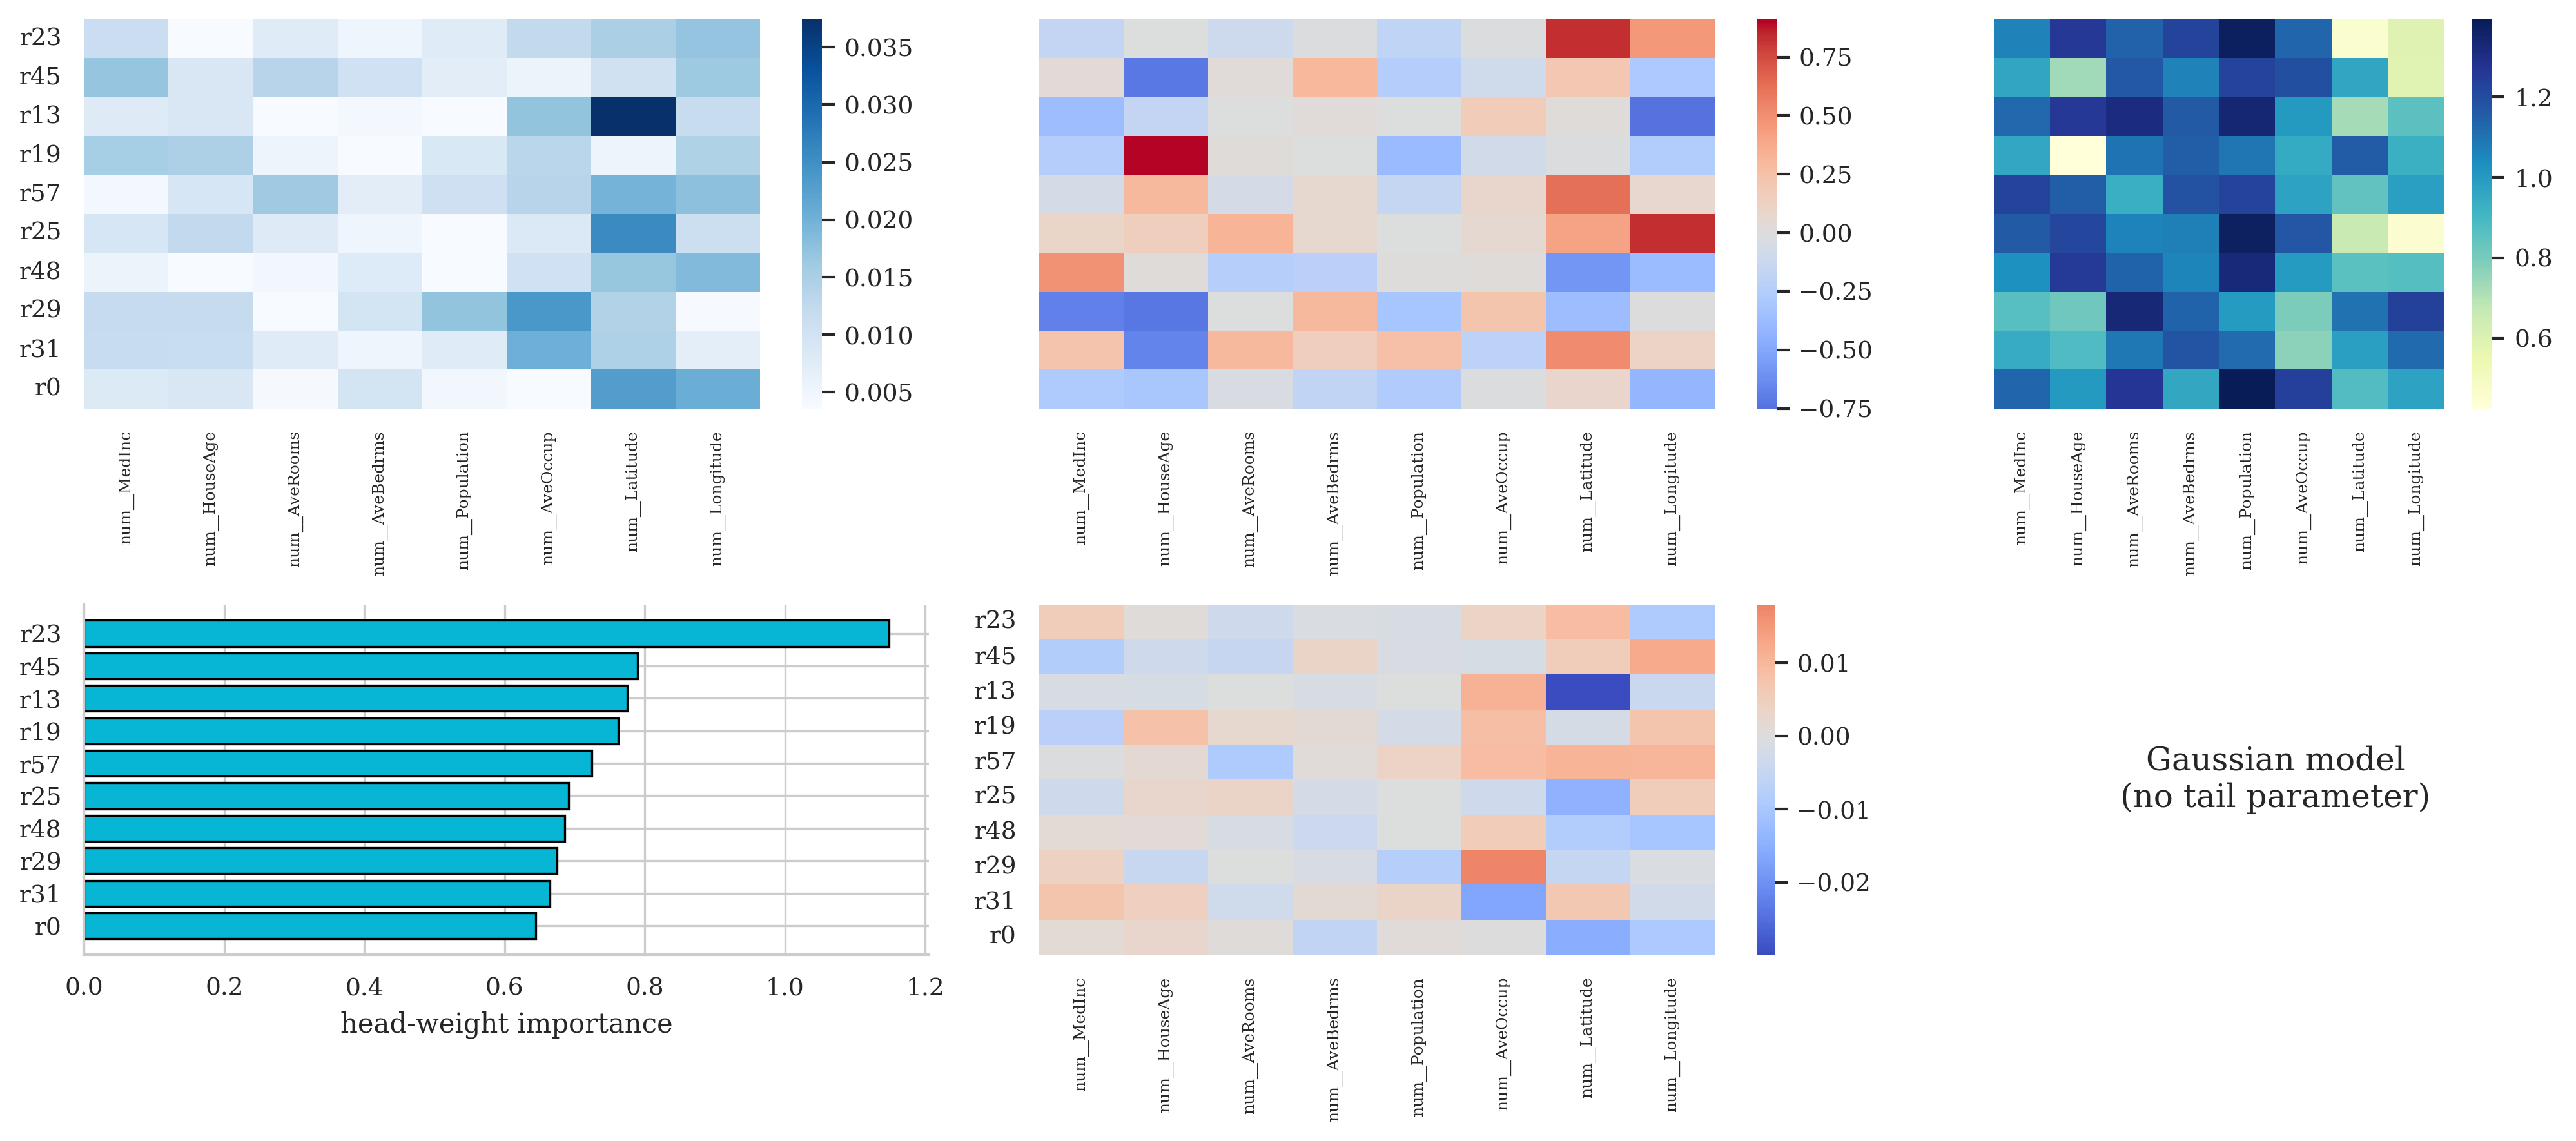

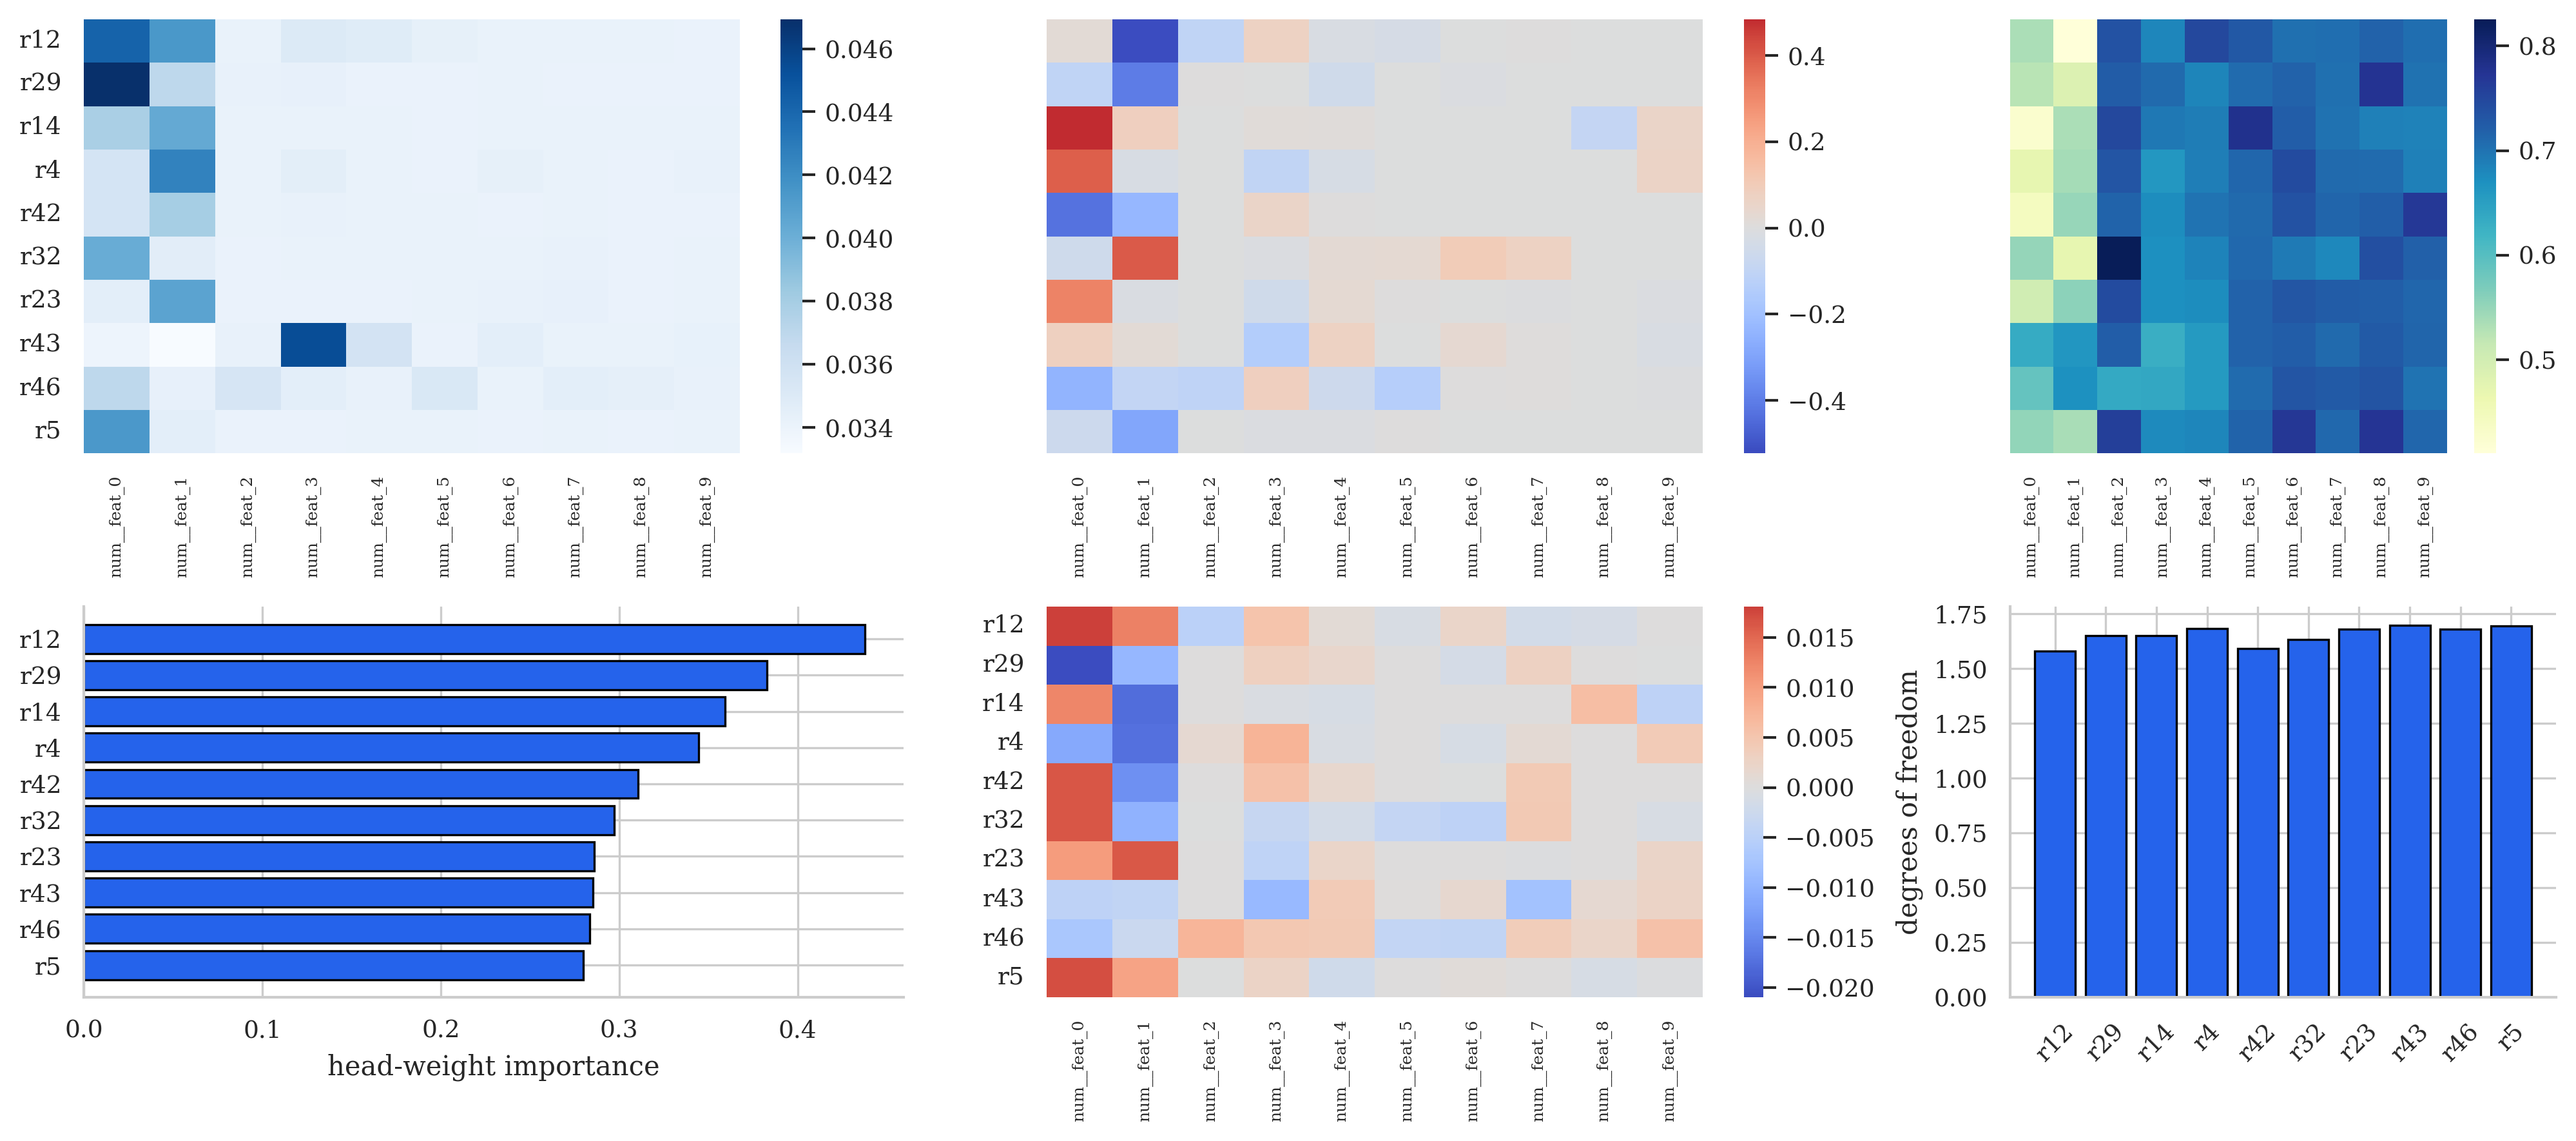

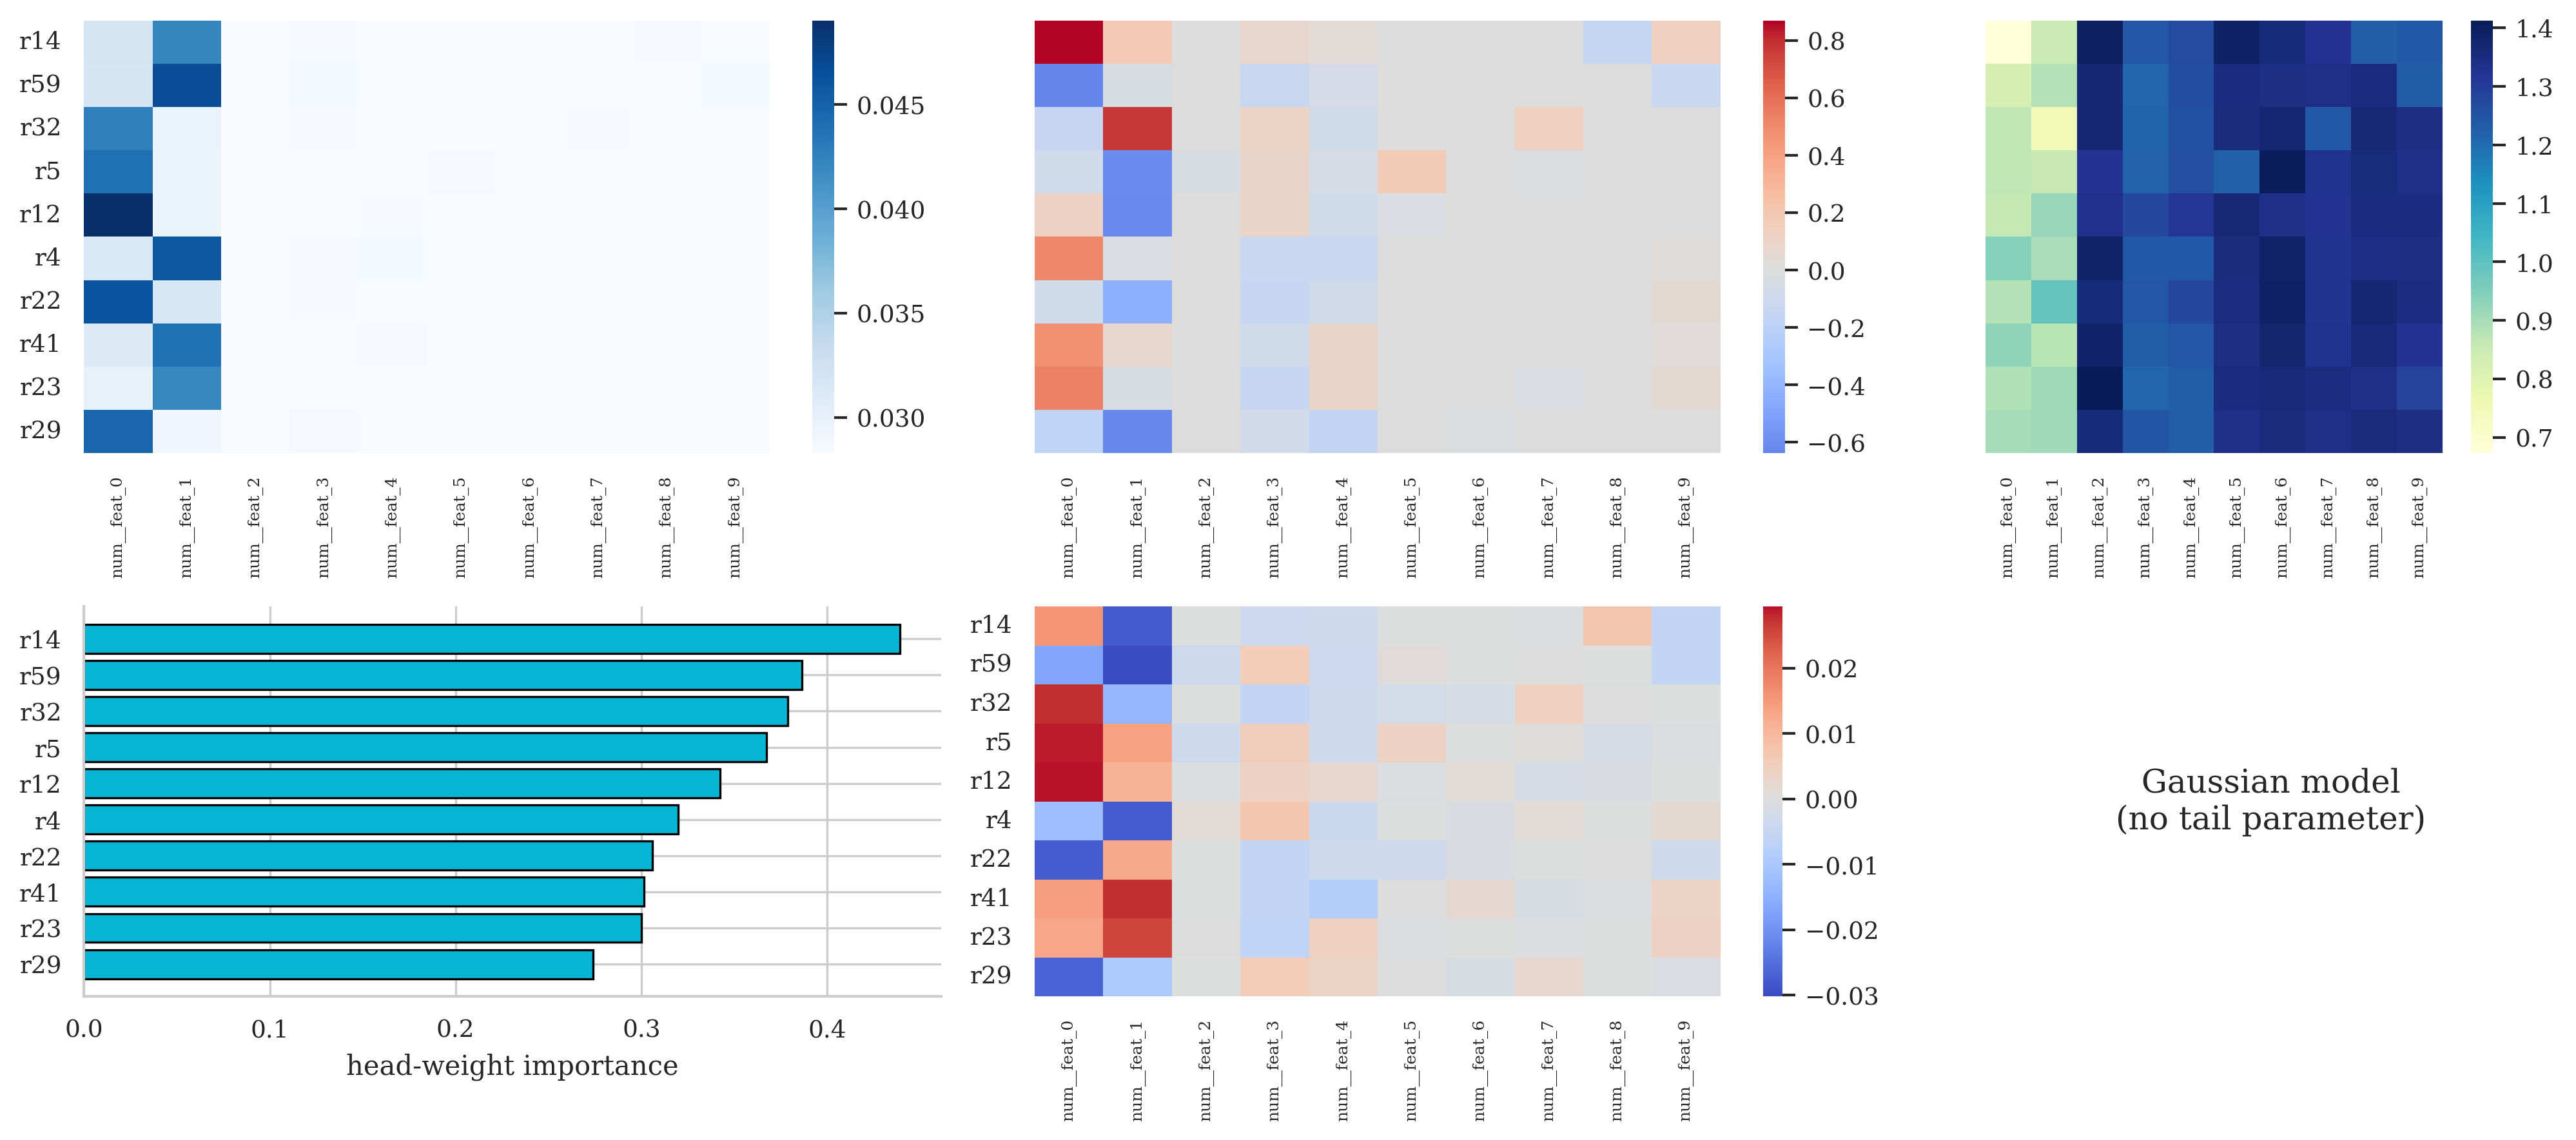

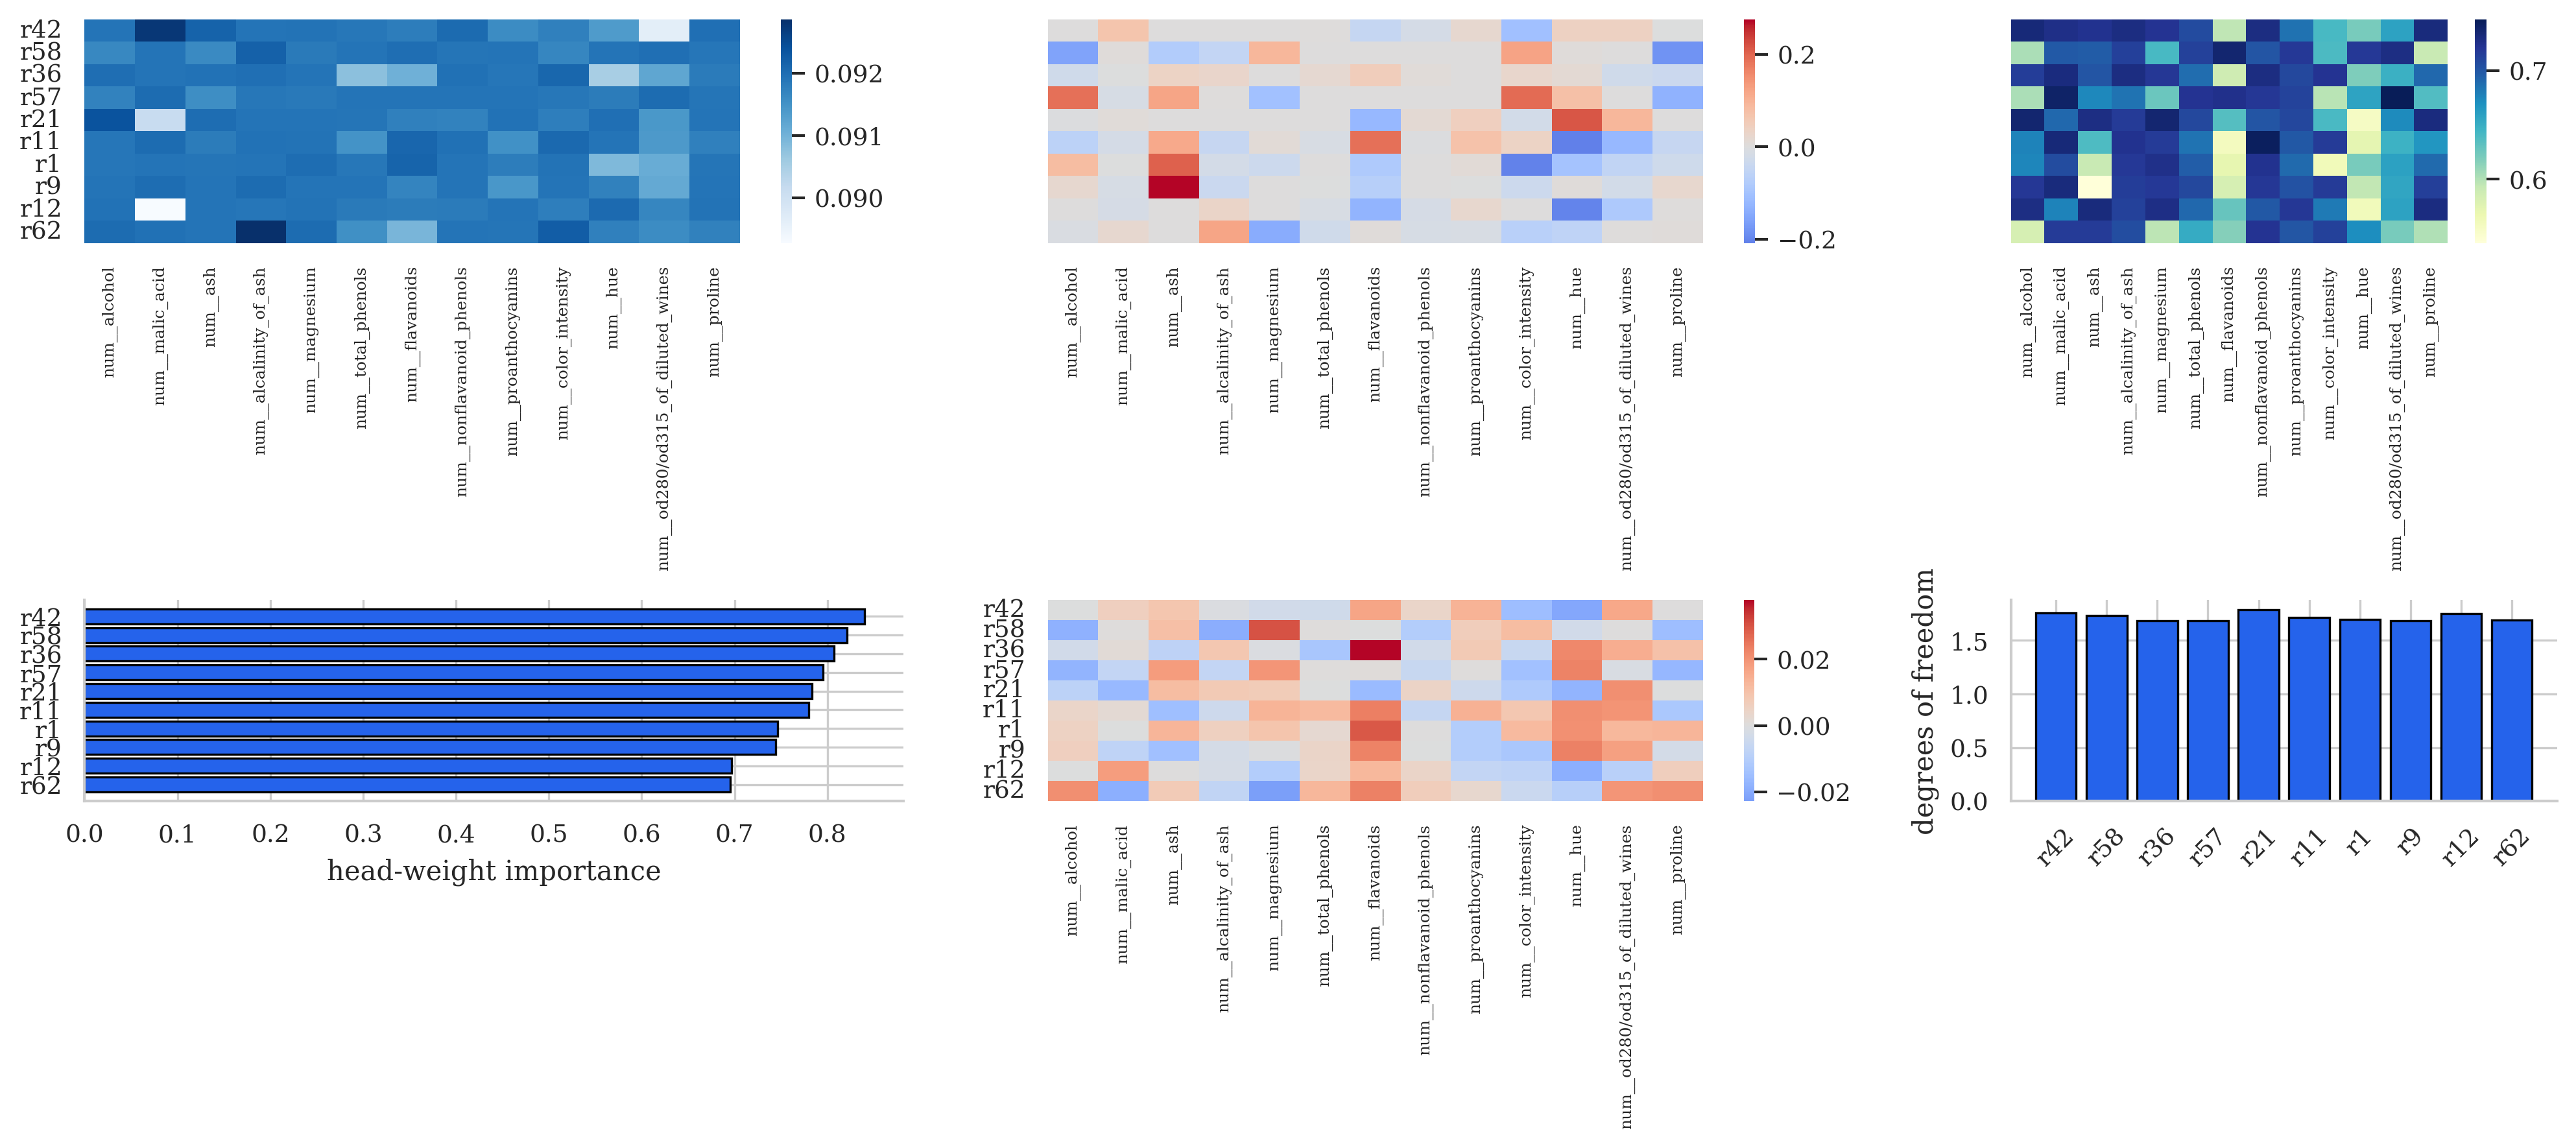

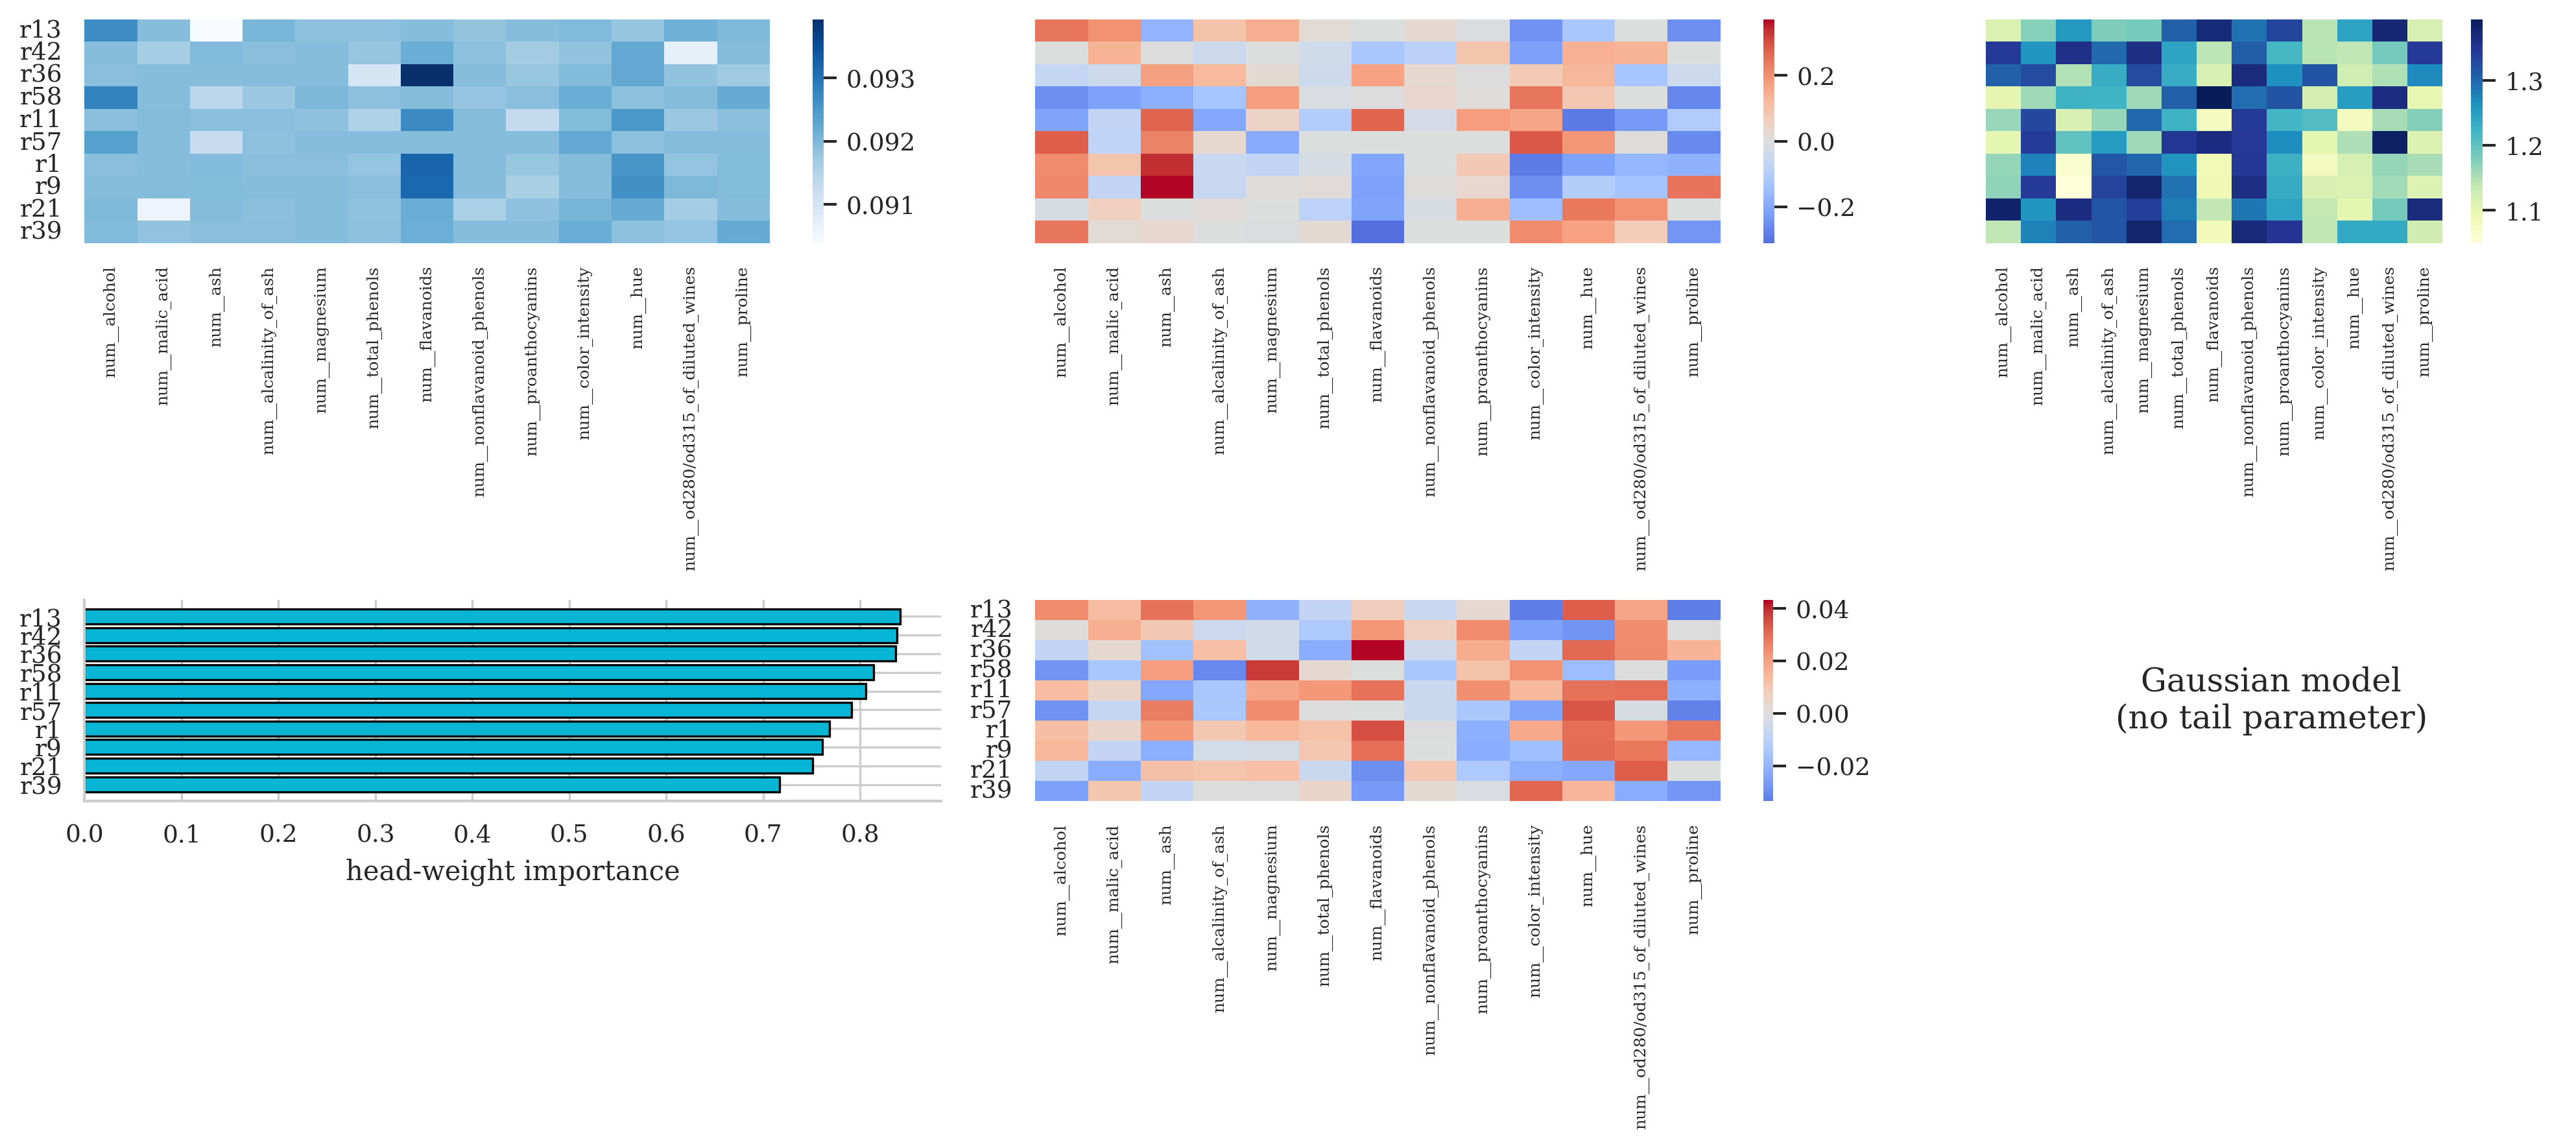

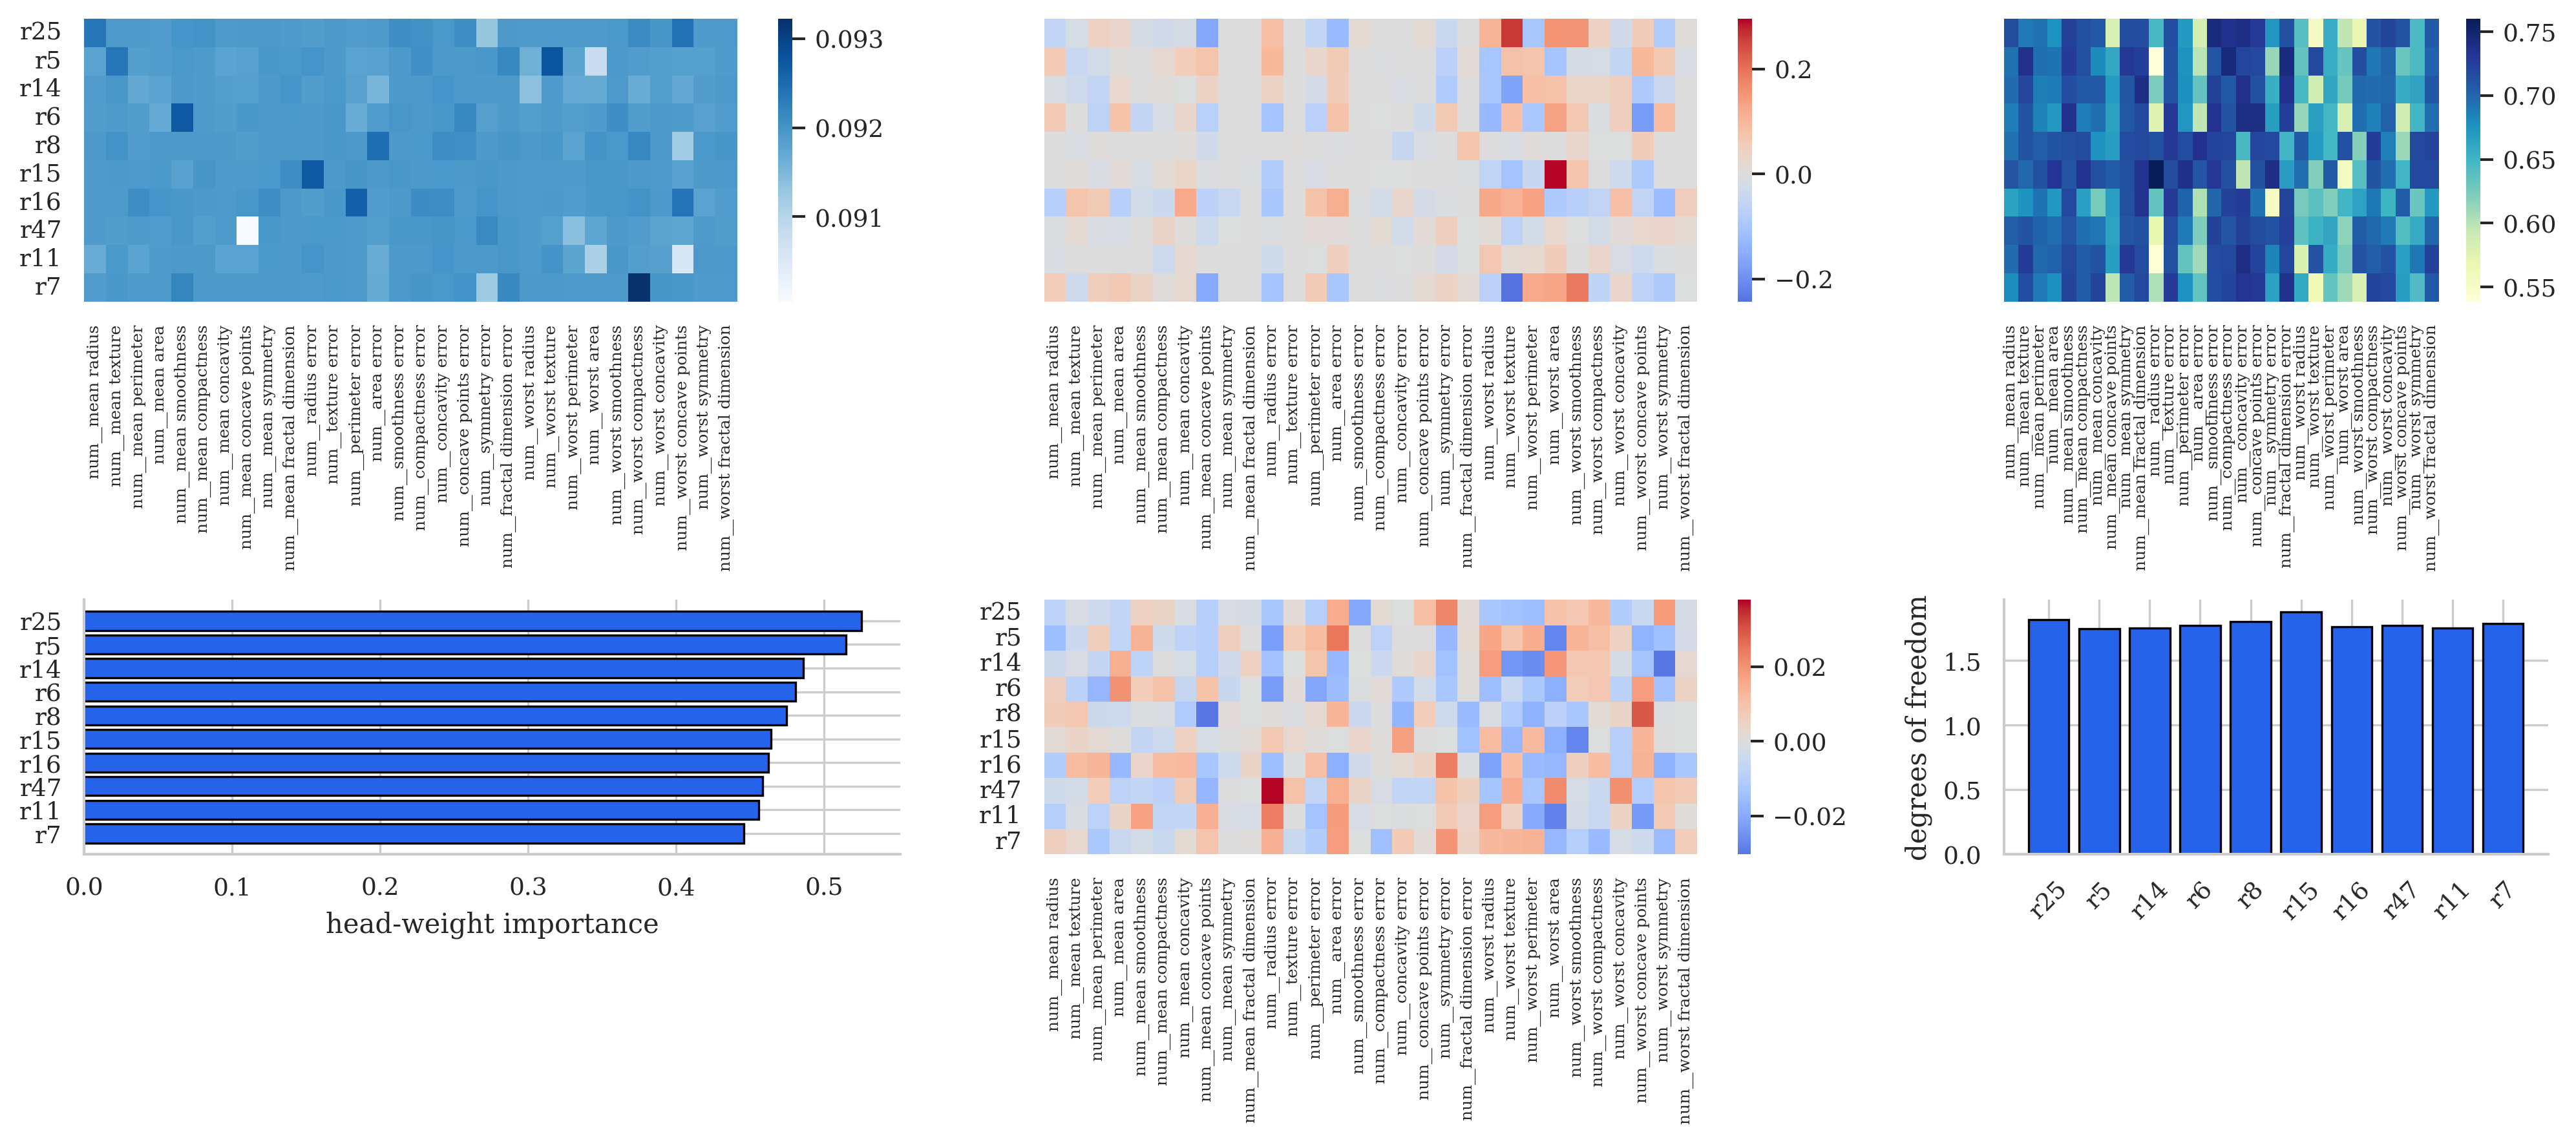

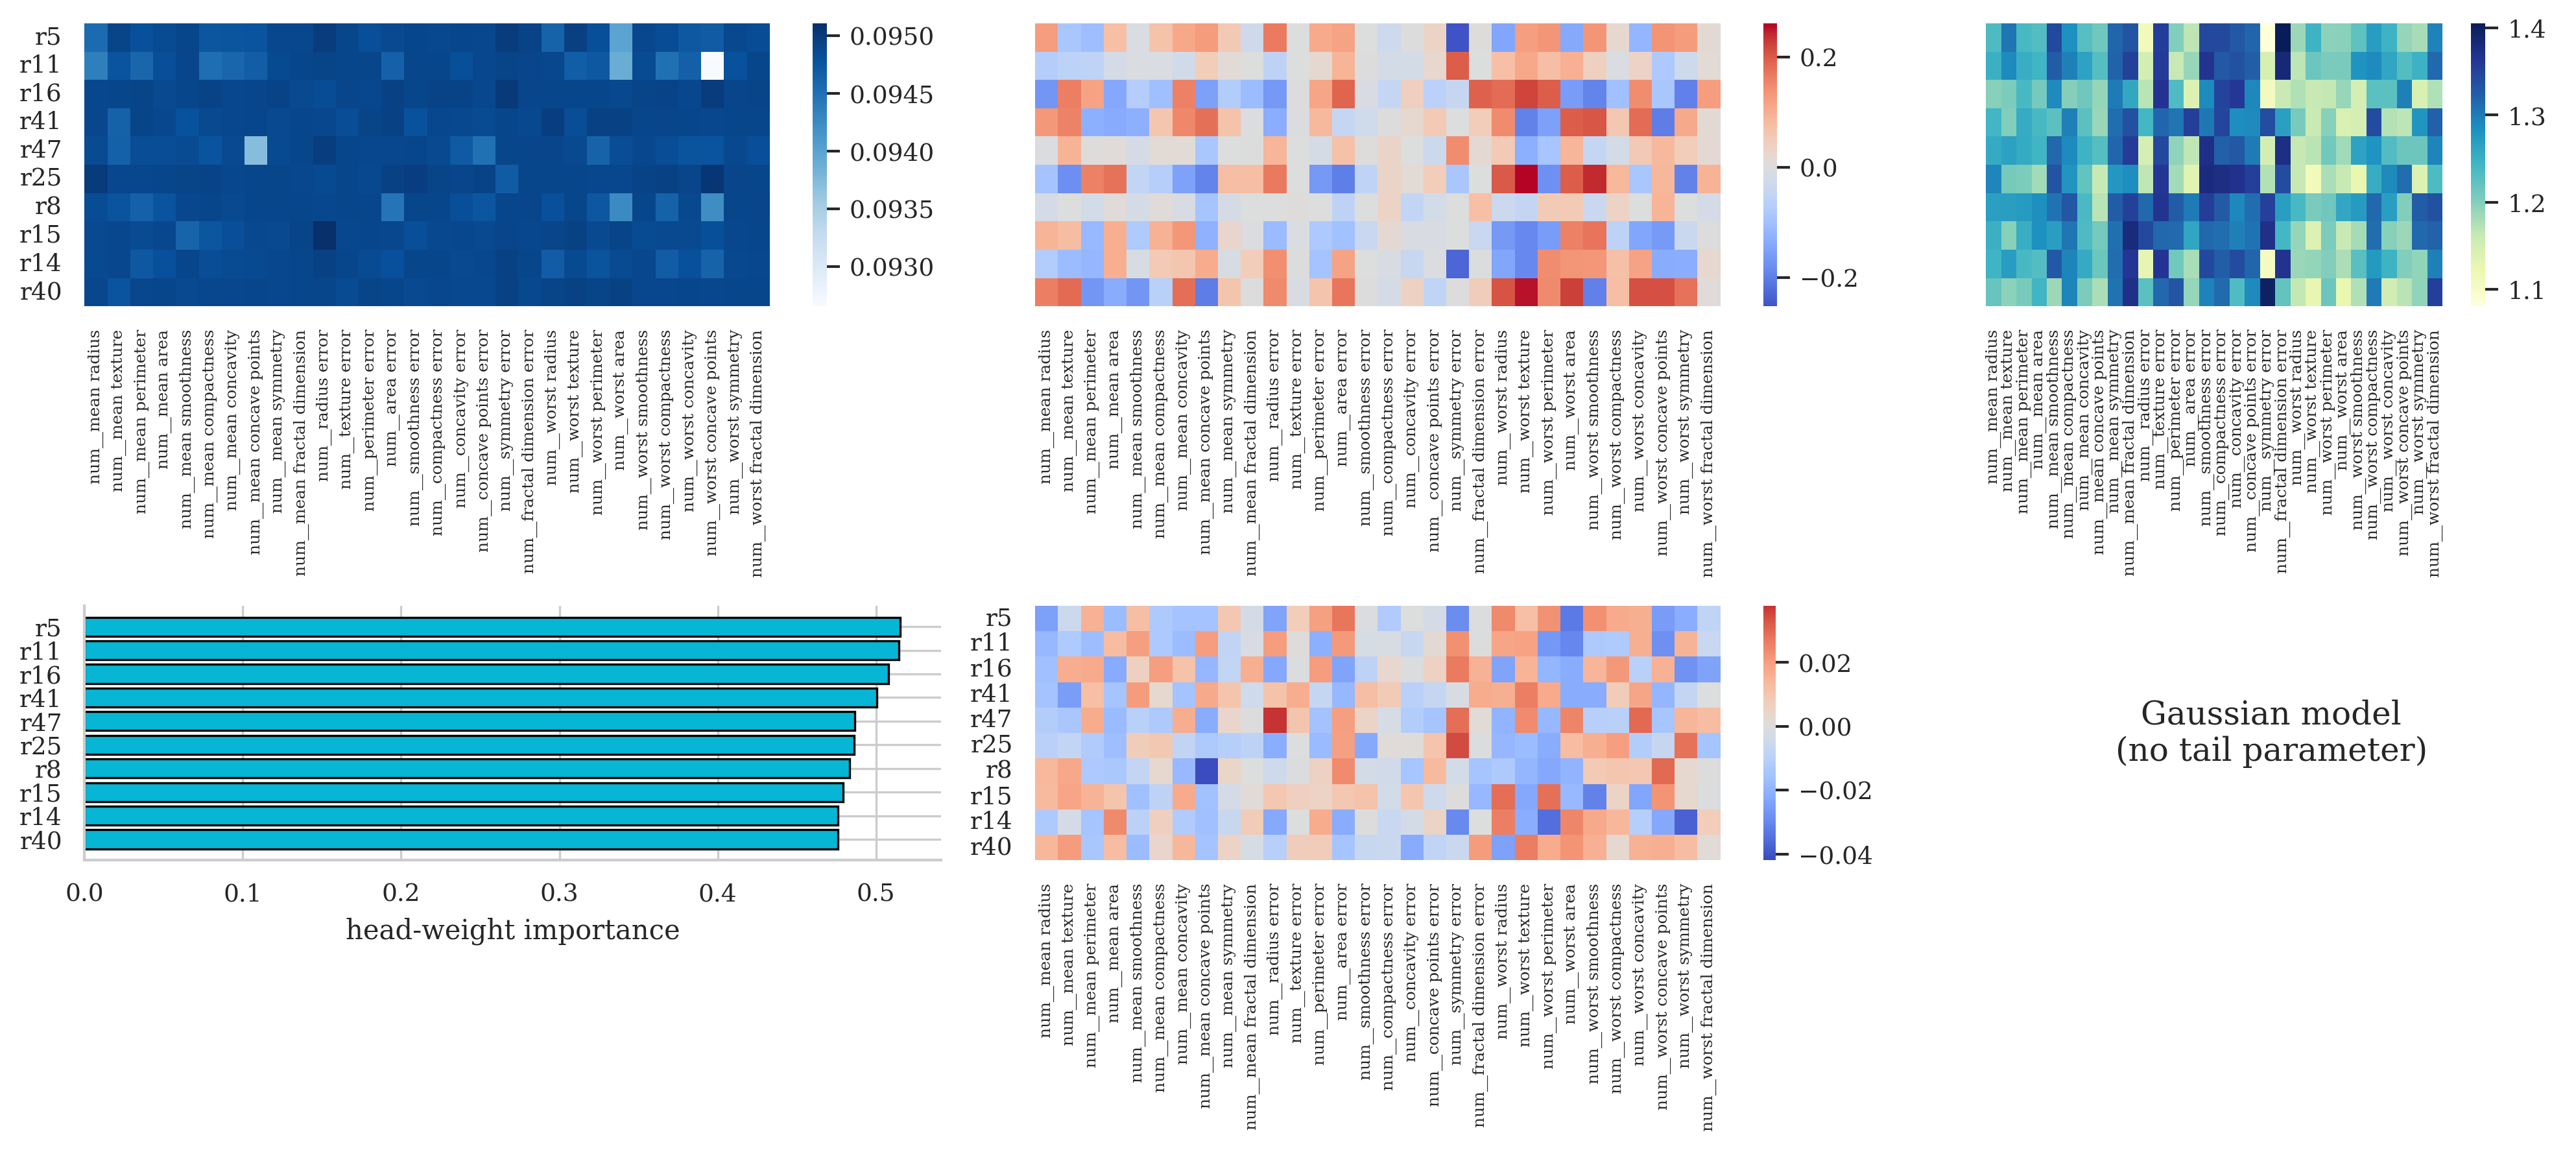

In [17]:
def top_rule_indices(model, k=10):
    with torch.no_grad():
        w = model.head.weight.detach().cpu().numpy()
        importance = np.abs(w).sum(axis=0)
        idx = np.argsort(importance)[::-1][:k]
    return idx, importance

def extract_rule_structure(model):
    with torch.no_grad():
        mask = torch.sigmoid(model.rules.mask_logit).detach().cpu().numpy()
        th = model.rules.th.detach().cpu().numpy()
        direction = torch.tanh(model.rules.ineq).detach().cpu().numpy()
        evidence_sign = torch.tanh(model.rules.esign).detach().cpu().numpy()

    return mask, th, direction, evidence_sign

def plot_model_structure(ds_name: str, model_name: str, top_k: int = 10):
    key = (ds_name, model_name)
    if key not in example_models:
        print(f"No stored example for {key}.")
        return

    model = example_models[key]
    pp = example_data[ds_name]
    idx, importance = top_rule_indices(model, k=top_k)
    mask, th, direction, evidence_sign = extract_rule_structure(model)

    if model_name == "SMTE":
        loc = model.mu.detach().cpu().numpy()
        scale = F.softplus(model.log_s).detach().cpu().numpy()
        nu = F.softplus(model.log_nu).detach().cpu().numpy()
    else:
        loc = model.loc.detach().cpu().numpy()
        scale = F.softplus(model.scale).detach().cpu().numpy()
        nu = None

    feature_labels = pp.feature_names
    if len(feature_labels) > 35:
        show_cols = np.argsort(mask[idx].mean(axis=0))[::-1][:35]
    else:
        show_cols = np.arange(len(feature_labels))

    fig = plt.figure(figsize=(13.5, 6.0))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.0, 0.9], width_ratios=[1.2, 1.2, 0.8])

    ax0 = fig.add_subplot(gs[0, 0])
    
    mask_view = mask[idx][:, show_cols]
    mask_vmin = float(np.min(mask_view))
    mask_vmax = float(np.max(mask_view))
    if mask_vmax - mask_vmin < 1e-4:
        mask_vmax = mask_vmin + 1e-4

    sns.heatmap(
        mask_view,
        cmap="Blues",
        vmin=mask_vmin,
        vmax=mask_vmax,
        xticklabels=[feature_labels[j] for j in show_cols],
        yticklabels=[f"r{r}" for r in idx],
        cbar=True,
        ax=ax0,
    )
    ax0.tick_params(axis="x", rotation=90, labelsize=6)
    ax0.tick_params(axis="y", rotation=0)

    ax1 = fig.add_subplot(gs[0, 1])
    sns.heatmap(
        loc[idx][:, show_cols],
        cmap="coolwarm",
        center=0,
        xticklabels=[feature_labels[j] for j in show_cols],
        yticklabels=False,
        cbar=True,
        ax=ax1,
    )
    ax1.tick_params(axis="x", rotation=90, labelsize=6)

    ax2 = fig.add_subplot(gs[0, 2])
    sns.heatmap(
        scale[idx][:, show_cols],
        cmap="YlGnBu",
        xticklabels=[feature_labels[j] for j in show_cols],
        yticklabels=False,
        cbar=True,
        ax=ax2,
    )
    ax2.tick_params(axis="x", rotation=90, labelsize=6)

    ax3 = fig.add_subplot(gs[1, 0])
    ax3.barh(np.arange(len(idx)), importance[idx], color=MODEL_COLORS.get(model_name, "#777777"), edgecolor="black")
    ax3.set_yticks(np.arange(len(idx)))
    ax3.set_yticklabels([f"r{r}" for r in idx])
    ax3.tick_params(axis="y", rotation=0)
    ax3.invert_yaxis()
    ax3.set_xlabel("head-weight importance")

    ax4 = fig.add_subplot(gs[1, 1])
    signed_strength = (mask[idx] * evidence_sign[idx])[:, show_cols]
    sns.heatmap(
        signed_strength,
        cmap="coolwarm",
        center=0,
        xticklabels=[feature_labels[j] for j in show_cols],
        yticklabels=[f"r{r}" for r in idx],
        cbar=True,
        ax=ax4,
    )
    ax4.tick_params(axis="x", rotation=90, labelsize=6)
    ax4.tick_params(axis="y", rotation=0)

    ax5 = fig.add_subplot(gs[1, 2])
    if nu is not None:
        ax5.bar(np.arange(len(idx)), nu[idx], color=MODEL_COLORS.get(model_name, "#777777"), edgecolor="black")
        ax5.set_xticks(np.arange(len(idx)))
        ax5.set_xticklabels([f"r{r}" for r in idx], rotation=45)
        ax5.set_ylabel("degrees of freedom")
    else:
        ax5.axis("off")
        ax5.text(0.5, 0.5, "Gaussian model\n(no tail parameter)", ha="center", va="center", fontsize=12)

    plt.tight_layout()
    savefig(f"figure_7_structure_{model_name}_{ds_name}")
    plt.show()

for ds in STORE_EXAMPLE_DATASETS:
    for model_name in ["SMTE", "GMTE"]:
        if (ds, model_name) in example_models:
            plot_model_structure(ds, model_name, top_k=10)

## 16. Figure 8 — Optimization traces for stored proposed-model examples

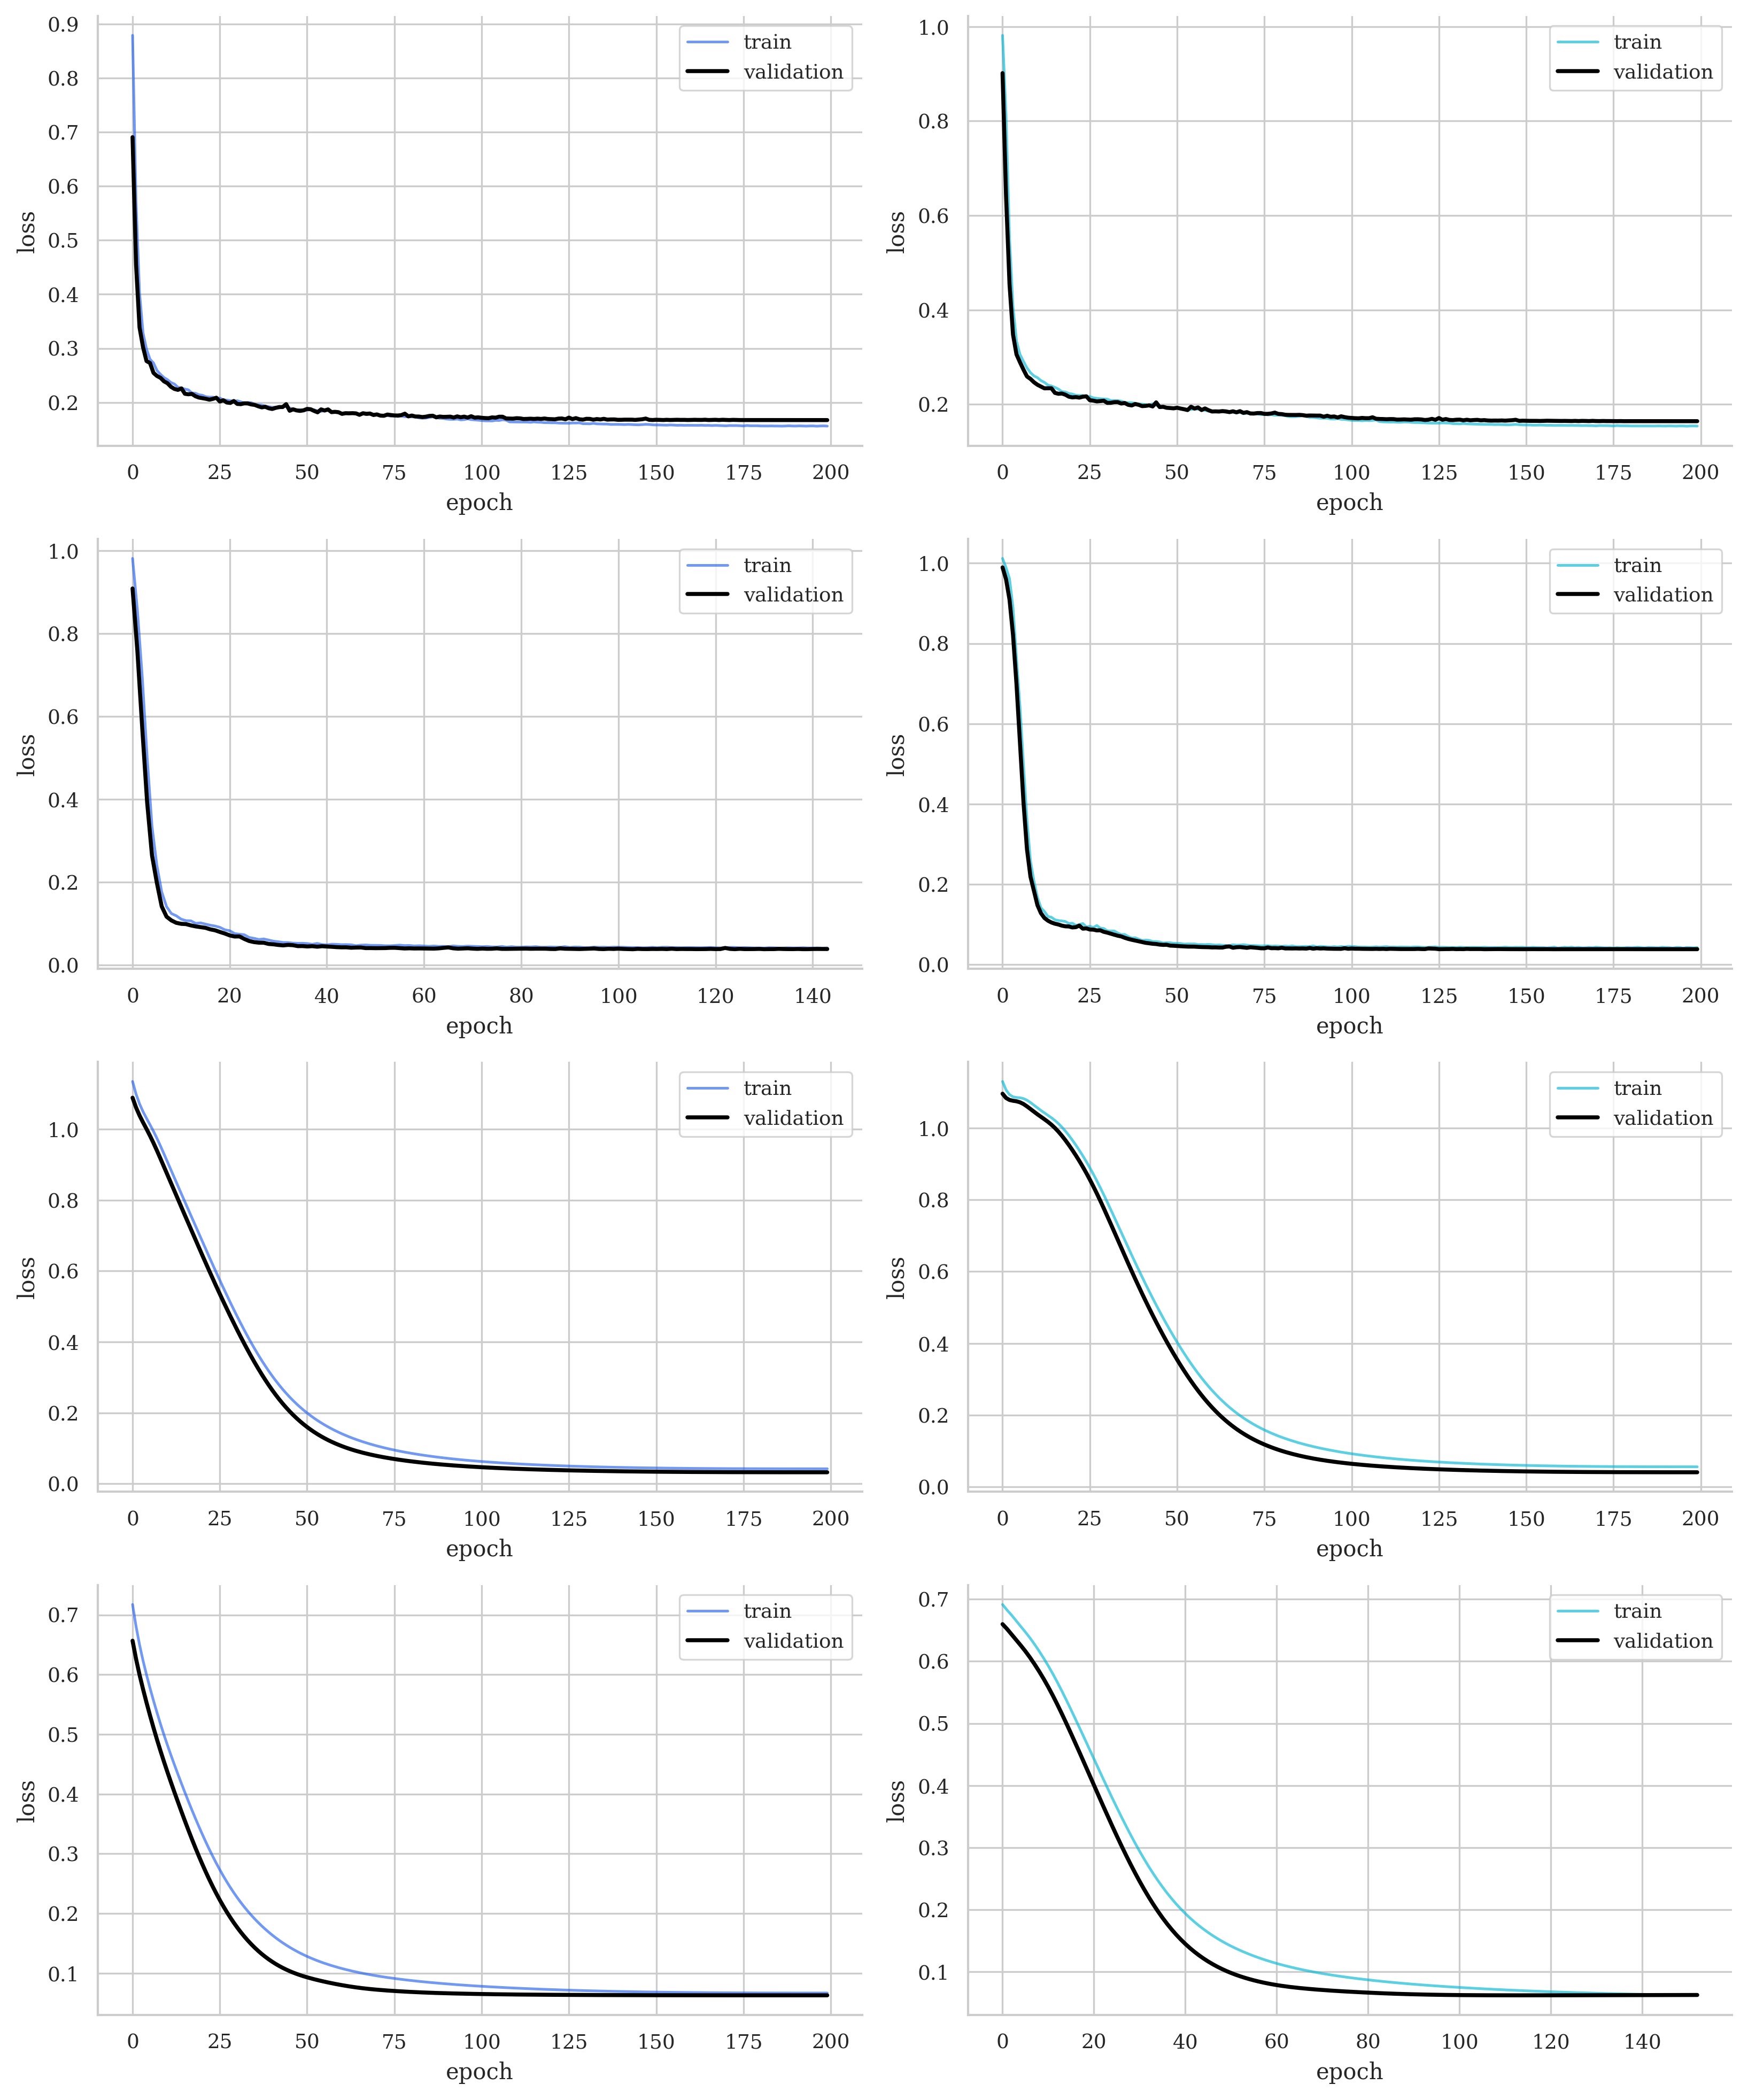

In [18]:
if example_histories:
    n = len(example_histories)
    cols = 2
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(11.0, 3.3 * rows), squeeze=False)
    axes = axes.flatten()

    for ax, ((ds_name, model_name), hist) in zip(axes, example_histories.items()):
        ax.plot(hist["train_loss"], label="train", color=MODEL_COLORS.get(model_name, "#777777"), alpha=0.65)
        ax.plot(hist["val_loss"], label="validation", color="black", linewidth=1.8)
        ax.set_xlabel("epoch")
        ax.set_ylabel("loss")
        ax.legend(frameon=True)

    for ax in axes[len(example_histories):]:
        ax.axis("off")

    plt.tight_layout()
    savefig("figure_8_optimization_traces")
    plt.show()

## 17. Extracted rule table for proposed models

In [19]:
def extract_human_rules(model, pp: PreparedData, top_k=8):
    idx, importance = top_rule_indices(model, k=top_k)
    mask, th, direction, evidence_sign = extract_rule_structure(model)

    rows = []
    for r in idx:
        threshold = max(0.01, 0.25 * float(mask[r].max()))
        active = np.where(mask[r] > threshold)[0]

        if len(active) == 0:
            rows.append({
                "RuleID": int(r),
                "Importance": float(importance[r]),
                "Conditions": "(no active literals)",
                "NumConditions": 0,
            })
            continue

        conds = []
        for j in active[:12]:
            op = ">" if direction[r, j] > 0 else "<"
            ev = "+" if evidence_sign[r, j] > 0 else "-"
            fname = pp.feature_names[j]
            conds.append(f"{fname} {op} {th[r, j]:+.3f} [{ev}, m={mask[r, j]:.2f}]")

        if len(active) > 12:
            conds.append(f"... +{len(active) - 12} more")

        rows.append({
            "RuleID": int(r),
            "Importance": float(importance[r]),
            "Conditions": " AND ".join(conds),
            "NumConditions": int(len(active)),
        })

    return pd.DataFrame(rows)

rule_tables = []

for (ds_name, model_name), model in example_models.items():
    pp = example_data[ds_name]
    tbl = extract_human_rules(model, pp, top_k=8)
    tbl.insert(0, "Dataset", ds_name)
    tbl.insert(1, "Model", model_name)
    rule_tables.append(tbl)

if rule_tables:
    rule_report = pd.concat(rule_tables, ignore_index=True)
    rule_report.to_csv(f"{OUTDIR}/table_extracted_rules.csv", index=False)
    display(rule_report)
else:
    print("No stored proposed-model examples were available for rule extraction.")

,Dataset,Model,RuleID,Importance,Conditions,NumConditions
0,California,SMTE,32,1.0377,"num__MedInc < +0.455 [+, m=0.01] AND num__AveO...",4
1,California,SMTE,23,1.0195,"num__AveOccup > -0.132 [+, m=0.02] AND num__La...",2
2,California,SMTE,25,1.0193,"num__MedInc > +1.177 [-, m=0.01] AND num__Hous...",4
3,California,SMTE,0,0.9225,"num__MedInc < -0.676 [+, m=0.02] AND num__Hous...",4
4,California,SMTE,9,0.7500,"num__AveBedrms < -0.202 [-, m=0.01] AND num__L...",3
...,...,...,...,...,...,...
59,BreastCancer,GMTE,41,0.5008,"num__mean radius < +0.071 [-, m=0.09] AND num_...",30
60,BreastCancer,GMTE,47,0.4865,"num__mean radius > -0.460 [-, m=0.09] AND num_...",30
61,BreastCancer,GMTE,25,0.4861,"num__mean radius < +0.609 [-, m=0.10] AND num_...",30
62,BreastCancer,GMTE,8,0.4834,"num__mean radius > +1.443 [+, m=0.09] AND num_...",30


## 18. Final summary

In [20]:
best_global = global_summary.iloc[0]
best_proposed = global_summary[global_summary["Group"] == "Proposed"].sort_values("AvgRank").iloc[0]
best_baseline = global_summary[global_summary["Group"] == "Baseline"].sort_values("AvgRank").iloc[0]

print("\n" + "=" * 90)
print("BENCHMARK SUMMARY")
print("=" * 90)

print(f"Best overall model       : {best_global['Model']}  | AvgRank={best_global['AvgRank']:.3f}")
print(f"Best proposed model      : {best_proposed['Model']} | AvgRank={best_proposed['AvgRank']:.3f}")
print(f"Best baseline model      : {best_baseline['Model']} | AvgRank={best_baseline['AvgRank']:.3f}")
print(f"Datasets evaluated       : {df_ranked['Dataset'].nunique()} / {len(ALL_TASKS)}")
print(f"Dataset × seed blocks    : {df_ranked.groupby(['Dataset', 'Seed']).ngroups}")
print(f"Total successful records : {len(df_ranked)}")
print(f"Total failed records     : {len(df_fail)}")

print("\nFiles saved:")
for fname in sorted(os.listdir(OUTDIR)):
    print(f"  {fname}")


BENCHMARK SUMMARY
Best overall model       : EBM  | AvgRank=3.021
Best proposed model      : SMTE | AvgRank=3.104
Best baseline model      : EBM | AvgRank=3.021
Datasets evaluated       : 28 / 28
Dataset × seed blocks    : 140
Total successful records : 840
Total failed records     : 0

Files saved:
  failed_runs.csv
  figure_1_average_rank_cd.png
  figure_2_dataset_performance_heatmap.png
  figure_3_efficiency_frontier.png
  figure_4_pairwise_win_matrix.png
  figure_5_task_rank_profile.png
  figure_6_rank_distribution.png
  figure_7_structure_GMTE_BreastCancer.png
  figure_7_structure_GMTE_California.png
  figure_7_structure_GMTE_Friedman1.png
  figure_7_structure_GMTE_Wine.png
  figure_7_structure_SMTE_BreastCancer.png
  figure_7_structure_SMTE_California.png
  figure_7_structure_SMTE_Friedman1.png
  figure_7_structure_SMTE_Wine.png
  figure_8_optimization_traces.png
  ranked_benchmark_results.csv
  raw_benchmark_results.csv
  table_dataset_summary.csv
  table_dataset_winners.csv
  